# 4.2 กำลังคนเพิ่มขึ้นเมื่อเทียบกับอะไร — ประชากร บริการ และความจำเป็น

หัวข้อ 4.1 แสดงว่าจำนวนเพิ่มขึ้น หัวข้อนี้ถามว่า **เพิ่มขึ้นเมื่อเทียบกับอะไร** เพราะตัวหารแต่ละชนิดแทนความรับผิดชอบคนละแบบ

| ส่วน | คำถาม | ขอบเขต |
|---|---|---|
| 4.2.1 | กำลังคนต่อประชากรเปลี่ยนไปอย่างไร เมื่อเปลี่ยนขอบเขตบุคลากรและทะเบียนประชากร | ระดับประเทศ รวมกรุงเทพฯ 2556–2568 |
| 4.2.2 | บริการต่อบุคลากรเปลี่ยนไปอย่างไร และเลขคณิตเวลาทำงานบอกอะไรได้/ไม่ได้ | ขอบเขตบุคลากร-บริการที่จับคู่กัน (76 จังหวัด) |
| 4.2.3 | อายุ โรคที่บันทึก เศรษฐกิจ และทรัพยากร ทำนายบริการได้เพียงใด (M0–M5) และบริการคาดหมายภายใต้เงื่อนไขอ้างอิงเดียวกันเป็นอย่างไร | 76 จังหวัด 2565–2568 |
| 4.2.4 | ตัวหารที่ต่างกันให้ภาพความก้าวหน้าต่างกันอย่างไร | ช่วงยาวและช่วงร่วม |

ผลลัพธ์ที่หัวข้อ 4.3 ใช้ต่อ (ตัวหารมาตรฐาน M5 และน้ำหนักอายุ) ถูกส่งออกที่ `outputs/chapter4_2/tables/` เท่านั้น

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "analysis.toml").exists())
sys.path.insert(0, str(_root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from chapter4 import config as C, panels as P, metrics as M, models as MD, reporting as R
from chapter4.ingest import load

pd.options.display.max_columns = 40
pd.options.display.width = 200
FONT = R.setup_style()
S = R.Section("4_2")
Y0, Y1 = C.Y0, C.Y1
CAD = C.CADRES
EN = C.CADRE_EN
BK = int(P.key().query("is_bangkok").prov_code.iloc[0])
UNI_TH = {"all_sectors": "ทุกสังกัด", "public_total": "ภาครัฐรวม", "moph": "กระทรวงสาธารณสุข"}
REG_TH = {"civil_age": "ทะเบียนราษฎร (แจกแจงอายุได้)", "civil_grand": "ทะเบียนราษฎร (ยอดรวม)", "nhso_rights": "ทะเบียนสิทธิ สปสช."}
print(C.effective_config("4_2"))

{
 "years": {
  "long_first": 2013,
  "long_last": 2025,
  "casemix_first": 2018,
  "casemix_last": 2025,
  "morbidity_first": 2022,
  "morbidity_last": 2025,
  "flow_first_fy": 2017,
  "flow_last_complete_fy": 2025,
  "recent_window_years": 5,
  "pre_transfer_last": 2022,
  "covid_years": [
   2020,
   2021,
   2022
  ]
 },
 "cadres": {
  "main": [
   "แพทย์",
   "พยาบาลวิชาชีพ",
   "เภสัชกร",
   "ทันตแพทย์"
  ],
  "diagnostic": [
   "พยาบาลเทคนิค"
  ],
  "combined_reference": [
   "แพทย์",
   "พยาบาลวิชาชีพ"
  ],
  "nurse_includes_technical": true,
  "en": {
   "แพทย์": "physicians",
   "พยาบาลวิชาชีพ": "professional_nurses",
   "เภสัชกร": "pharmacists",
   "ทันตแพทย์": "dentists",
   "พยาบาลเทคนิค": "technical_nurses"
  }
 },
 "universes": {
  "workforce": {
   "all_sectors": [
    "moph",
    "other_public",
    "private",
    "unclassified"
   ],
   "public_total": [
    "moph",
    "other_public"
   ],
   "moph": [
    "moph"
   ]
  }
 },
 "benchmark": {
  "value_per_1000": 4.45,

---
# ส่วน A — 4.2.1 เทียบกับจำนวนประชากร

## A1. ทะเบียนประชากรสามชุด
แฟ้มรายอายุนับเฉพาะคนสัญชาติไทยในทะเบียนบ้านปกติที่ระบุอายุได้ แฟ้มยอดรวมเพิ่มอีกสี่กลุ่ม
(มิใช่สัญชาติไทย ทะเบียนบ้านกลาง ระหว่างย้าย เกิดปีจันทรคติ) ส่วนทะเบียนสิทธิเป็นการลงทะเบียนสิทธิการรักษา
ซึ่งไม่ใช่ชุดที่ครอบทะเบียนราษฎรโดยอัตโนมัติ

In [2]:
parts = load("population_register_parts")
assert parts.identity_gap.abs().max() == 0 and (parts.file_grand_total == parts.national_row).all()
S.table("T421_REGISTER_DECOMPOSITION", parts, "องค์ประกอบของทะเบียนราษฎร: ส่วนที่แจกแจงอายุได้ และสี่กลุ่มที่แจกแจงไม่ได้ (ทั้งประเทศ)", main=True)
p25 = parts.set_index("year").loc[Y1]
for k_ in ["age_attributed", "file_grand_total", "non_thai_nationality", "central_household_registry", "in_transit", "lunar_birth_year", "nhso_national_total"]:
    S.claim(f"c421_pop2025_{k_}", p25[k_], "int", "คน", "T421_REGISTER_DECOMPOSITION", f"year={Y1}", k_)
p13 = parts.set_index("year").loc[Y0]
S.claim("c421_pop2013_age_attributed", p13.age_attributed, "int", "คน")
S.claim("c421_pop_cagr", 100 * M.cagr(p13.age_attributed, p25.age_attributed, Y1 - Y0), "{:.2f}", "% ต่อปี")
S.claim("c421_pop_pct", M.pct_change(p13.age_attributed, p25.age_attributed), "{:.2f}", "%")
S.claim("c421_grand_vs_age_density_pct", 100 * (p25.age_attributed / p25.file_grand_total - 1), "{:.2f}", "%",
        note="ผลต่อความหนาแน่นเมื่อเปลี่ยนจากแฟ้มรายอายุเป็นยอดรวม (บุคลากรคงเดิม)")
S.claim("c421_nhso_vs_age_pop_pct", 100 * (p25.nhso_national_total / p25.age_attributed - 1), "{:.2f}", "%")
S.claim("c421_nhso_vs_age_density_pct", 100 * (p25.age_attributed / p25.nhso_national_total - 1), "{:.2f}", "%")
display(parts[["year", "age_attributed", "non_thai_nationality", "central_household_registry", "in_transit", "file_grand_total", "nhso_national_total"]])

# the entitlement register: which right codes do not require regular house registration
nh = load("nhso_province_scheme_age")
nh25 = nh[(nh.year == Y1) & (nh.month == "12")]
OUTSIDE = {"NRD": "สถานะคนต่างด้าว", "NRH": "บุคคลต่างด้าวซื้อประกันสุขภาพ", "STP": "บุคคลผู้มีปัญหาสถานะและสิทธิ",
           "005": "ไม่อยู่ตามทะเบียนบ้าน (รอยืนยันสิทธิ)", "FRG": "คนไทยในต่างประเทศ", "XXX": "ยังไม่ลงทะเบียนตามมาตรา 6"}
out_codes = nh25[nh25.right_code.isin(OUTSIDE)].groupby("right_code").persons.sum()
recon = pd.DataFrame([
    dict(item="ทะเบียนสิทธิ ยอดรวม", persons=nh25.persons.sum()),
    dict(item="ทะเบียนราษฎร ยอดรวม", persons=p25.file_grand_total),
    dict(item="ส่วนต่าง: สิทธิ − ราษฎรยอดรวม", persons=nh25.persons.sum() - p25.file_grand_total),
    dict(item="ผู้มีสิทธิในรหัสที่ไม่ต้องมีชื่อในทะเบียนบ้านปกติ (" + ", ".join(out_codes.index) + ")", persons=out_codes.sum()),
    dict(item="ส่วนที่ยังอธิบายไม่ได้", persons=nh25.persons.sum() - p25.file_grand_total - out_codes.sum()),
    dict(item="ผู้มีสิทธิที่ไม่ระบุจังหวัด", persons=nh25[~nh25.prov_code.isin(P.key().prov_code)].persons.sum()),
])
S.table("T421_NHSO_RECONCILIATION", recon, f"กระทบยอดทะเบียนสิทธิกับทะเบียนราษฎร พ.ศ. {C.be(Y1)} (ระดับกลุ่ม ไม่ใช่การจับคู่รายคน)")
display(recon)
S.claim("c421_nhso_outside_codes", out_codes.sum(), "int", "คน")
S.claim("c421_nhso_unexplained", recon.persons.iloc[4], "int", "คน")

,year,age_attributed,non_thai_nationality,central_household_registry,in_transit,file_grand_total,nhso_national_total
0,2013,63650593.0,342708.0,637403.0,154763.0,64785909.0,65707696
1,2014,63954350.0,347367.0,664856.0,157716.0,65124716.0,66047118
2,2015,64219585.0,674026.0,675849.0,159222.0,65729098.0,66040761
3,2016,64417145.0,665753.0,693992.0,154607.0,65931550.0,66348586
4,2017,64627465.0,680549.0,722717.0,157722.0,66188503.0,66611083
5,2018,64816825.0,700672.0,742416.0,154017.0,66413979.0,66837266
6,2019,64929153.0,727926.0,751791.0,150019.0,66558935.0,67087319
7,2020,65007464.0,756907.0,393847.0,28462.0,66186727.0,67246408
8,2021,64956883.0,775786.0,416517.0,22223.0,66171439.0,67256768
9,2022,64867406.0,801073.0,402739.0,19230.0,66090475.0,67298366


,item,persons
0,ทะเบียนสิทธิ ยอดรวม,67115196.0
1,ทะเบียนราษฎร ยอดรวม,65809011.0
2,ส่วนต่าง: สิทธิ − ราษฎรยอดรวม,1306185.0
3,ผู้มีสิทธิในรหัสที่ไม่ต้องมีชื่อในทะเบียนบ้านป...,1307527.0
4,ส่วนที่ยังอธิบายไม่ได้,-1342.0
5,ผู้มีสิทธิที่ไม่ระบุจังหวัด,111392.0


-1342.0

## A2. ความหนาแน่นต่อประชากร: สามขอบเขตบุคลากร × สามทะเบียน

ตรวจเอกลักษณ์ของอัตราส่วน $1+g(W/P)=(1+g_W)/(1+g_P)$ อย่างแม่นตรง (ไม่ใช้ผลต่างของอัตราการเติบโต)

In [3]:
WFN = pd.concat([P.workforce_national(u) for u in ["all_sectors", "public_total", "moph"]], ignore_index=True)
POPN = pd.concat([P.population_national(r) for r in ["civil_age", "civil_grand", "nhso_rights"]], ignore_index=True)
# national densities use the national NHSO total, which keeps rights-holders without a province (D8);
# the provincial sum would differ from c421_nhso_vs_age_density_pct (final check M-1)
_nat_nhso = parts.set_index("year").nhso_national_total
_m = POPN.register == "nhso_rights"
POPN.loc[_m, "population"] = POPN.loc[_m, "year"].map(_nat_nhso).fillna(POPN.loc[_m, "population"])
DEN = WFN.merge(POPN, on="year")
DEN["density_per_100k"] = 1e5 * DEN.headcount / DEN.population
S.table("T421_DENSITY_ANNUAL", DEN, "ความหนาแน่นต่อประชากร 100,000 คน ตามวิชาชีพ ขอบเขตบุคลากร และทะเบียน")
DS = M.endpoint_summary(DEN.rename(columns={"density_per_100k": "value"}), ["cadre", "universe", "register"], y0=Y0, y1=Y1)
S.table("T421_DENSITY_ENDPOINTS", DS, "ความหนาแน่นต้นช่วงและปลายช่วง 2556–2568", main=True)
display(DS[DS.register == "civil_age"].pivot_table(index="cadre", columns="universe", values=["value_start", "value_end", "pct_change"]).round(2))
# exact ratio identity
idr = []
for _, r in DS.iterrows():
    w = WFN[(WFN.cadre == r.cadre) & (WFN.universe == r.universe)].set_index("year").headcount
    p = POPN[POPN.register == r.register].set_index("year").population
    gw, gp = M.cagr(w[Y0], w[Y1], Y1 - Y0), M.cagr(p[Y0], p[Y1], Y1 - Y0)
    idr.append(dict(cadre=r.cadre, universe=r.universe, register=r.register, cagr_D=r.cagr_pct / 100,
                    identity=M.ratio_cagr_identity(gw, gp), difference_approx=gw - gp))
IDR = pd.DataFrame(idr)
IDR["identity_gap"] = IDR.cagr_D - IDR.identity
assert IDR.identity_gap.abs().max() < 1e-12
S.table("T421_CAGR_IDENTITY", IDR, "ตรวจเอกลักษณ์อัตราการเติบโตของอัตราส่วน (ผลต่างอัตราเติบโตเป็นเพียงค่าประมาณ)")
for c in CAD:
    for u in ["all_sectors", "public_total", "moph"]:
        r = DS[(DS.cadre == c) & (DS.universe == u) & (DS.register == "civil_age")].iloc[0]
        S.claim(f"c421_dens_{EN[c]}_{u}_start", r.value_start, "{:.2f}", "ต่อ 100,000", "T421_DENSITY_ENDPOINTS")
        S.claim(f"c421_dens_{EN[c]}_{u}_end", r.value_end, "{:.2f}", "ต่อ 100,000", "T421_DENSITY_ENDPOINTS")
        S.claim(f"c421_dens_{EN[c]}_{u}_pct", r["pct_change"], "{:.2f}", "%", "T421_DENSITY_ENDPOINTS")
# MOPH share of physicians
ms = WFN.pivot_table(index=["year", "cadre"], columns="universe", values="headcount")
ms["moph_share_pct"] = 100 * ms.moph / ms.all_sectors
S.table("T421_MOPH_SHARE", ms.reset_index(), "สัดส่วนบุคลากรสังกัด สธ. ในบุคลากรทุกสังกัด")
for c in CAD:
    S.claim(f"c421_moph_share_{EN[c]}_start", ms.loc[(Y0, c), "moph_share_pct"], "{:.2f}", "%")
    S.claim(f"c421_moph_share_{EN[c]}_end", ms.loc[(Y1, c), "moph_share_pct"], "{:.2f}", "%")

pct_change                       value_end                      value_start                     
universe      all_sectors   moph public_total all_sectors    moph public_total all_sectors    moph public_total
cadre                                                                                                          
ทันตแพทย์           14.88  32.07        41.65       13.84    9.64        13.12       12.05    7.30         9.26
พยาบาลวิชาชีพ       44.89  25.53        36.85      314.61  192.74       265.71      217.13  153.54       194.16
เภสัชกร             50.82  50.20        58.25       26.42   16.93        21.28       17.52   11.27        13.45
แพทย์               69.11  50.15        62.72       71.11   36.97        56.06       42.05   24.62        34.45

## A3. แยกผลของ "การเปลี่ยนตัวหาร" ออกจาก "การเปลี่ยนขอบเขตบุคลากร"
$\ln D_{u,r}-\ln D_{\text{all},\text{civil\_age}}=\ln(W_u/W_{\text{all}})-\ln(P_r/P_{\text{civil\_age}})$ ปี 2568

In [4]:
dec = []
for c in CAD:
    base = DEN[(DEN.cadre == c) & (DEN.year == Y1) & (DEN.universe == "all_sectors") & (DEN.register == "civil_age")].iloc[0]
    for _, r in DEN[(DEN.cadre == c) & (DEN.year == Y1)].iterrows():
        dec.append(dict(cadre=c, universe=r.universe, register=r.register, density=r.density_per_100k,
                        log_total=np.log(r.density_per_100k / base.density_per_100k),
                        workforce_scope_effect=np.log(r.headcount / base.headcount),
                        denominator_effect=-np.log(r.population / base.population)))
DEC = pd.DataFrame(dec)
DEC["residual"] = DEC.log_total - DEC.workforce_scope_effect - DEC.denominator_effect
assert DEC.residual.abs().max() < 1e-12
DEC["pct_vs_base"] = 100 * (np.exp(DEC.log_total) - 1)
S.table("T421_SCOPE_VS_DENOMINATOR", DEC, "แยกผลของขอบเขตบุคลากรและตัวหารประชากรต่อความหนาแน่น ปี 2568 (log)", main=True)
display(DEC.pivot_table(index=["cadre", "universe"], columns="register", values="pct_vs_base").round(2))

register                    civil_age  civil_grand  nhso_rights
cadre         universe                                         
ทันตแพทย์     all_sectors        0.00        -1.84        -3.75
              moph             -30.35       -31.63       -32.96
              public_total      -5.18        -6.93        -8.74
พยาบาลวิชาชีพ all_sectors        0.00        -1.84        -3.75
              moph             -38.74       -39.86       -41.03
              public_total     -15.54       -17.10       -18.71
เภสัชกร       all_sectors        0.00        -1.84        -3.75
              moph             -35.94       -37.12       -38.34
              public_total     -19.46       -20.95       -22.49
แพทย์         all_sectors        0.00        -1.84        -3.75
              moph             -48.01       -48.97       -49.96
              public_total     -21.17       -22.62       -24.13

In [5]:
# ---- report-ready matrix: density by staffing scope (rows) and population register (columns), 2025
REG_ORDER = ["civil_age", "civil_grand", "nhso_rights"]
UNI_ORDER = ["all_sectors", "public_total", "moph"]
_m = DEC.pivot_table(index=["cadre", "universe"], columns="register", values="density").reindex(
    pd.MultiIndex.from_product([CAD, UNI_ORDER], names=["cadre", "universe"]))[REG_ORDER]
_scope = DEC[DEC.register == "civil_age"].set_index(["cadre", "universe"]).pct_vs_base
_reg = DEC[(DEC.universe == "all_sectors") & (DEC.cadre == CAD[0])].set_index("register").pct_vs_base
assert all(np.allclose(DEC[DEC.register == r].workforce_scope_effect.values, DEC[DEC.register == "civil_age"].workforce_scope_effect.values) for r in REG_ORDER)
rows = []
for (c, u), r in _m.iterrows():
    rows.append({"วิชาชีพ": c if u == "all_sectors" else "", "ขอบเขตบุคลากร": UNI_TH[u],
                 **{REG_TH[g]: f"{r[g]:,.2f}" for g in REG_ORDER},
                 "ต่างจากทุกสังกัด (ทะเบียนราษฎรแจกแจงอายุได้)": "–" if u == "all_sectors" else f"{_scope[(c, u)]:+.1f}%"})
rows.append({"วิชาชีพ": "ต่างจากทะเบียนราษฎร (แจกแจงอายุได้)", "ขอบเขตบุคลากร": "",
             **{REG_TH[g]: ("–" if g == "civil_age" else f"{_reg[g]:+.1f}%") for g in REG_ORDER},
             "ต่างจากทุกสังกัด (ทะเบียนราษฎรแจกแจงอายุได้)": ""})
MATRIX = pd.DataFrame(rows)
S.table("T421_DENSITY_SCOPE_REGISTER", MATRIX,
        f"ความหนาแน่นของกำลังคนต่อประชากร 100,000 คน พ.ศ. {C.be(Y1)} จำแนกตามขอบเขตบุคลากรและทะเบียนประชากร (พยาบาลวิชาชีพรวมพยาบาลเทคนิค)", main=True)
display(MATRIX)
for (c, u), v in _scope.items():
    if u != "all_sectors":
        S.claim(f"c421_scope_gap_{EN[c]}_{u}", v, "{:.1f}", "%", "T421_DENSITY_SCOPE_REGISTER")
for g in ["civil_grand", "nhso_rights"]:
    S.claim(f"c421_register_gap_{g}", _reg[g], "{:.1f}", "%", "T421_DENSITY_SCOPE_REGISTER")
_gaps = _scope[[k for k in _scope.index if k[1] != "all_sectors"]]
S.claim("c421_scope_gap_min_abs", _gaps.abs().min(), "{:.1f}", "%")
S.claim("c421_scope_gap_max_abs", _gaps.abs().max(), "{:.1f}", "%")

,วิชาชีพ,ขอบเขตบุคลากร,ทะเบียนราษฎร (แจกแจงอายุได้),ทะเบียนราษฎร (ยอดรวม),ทะเบียนสิทธิ สปสช.,ต่างจากทุกสังกัด (ทะเบียนราษฎรแจกแจงอายุได้)
0,แพทย์,ทุกสังกัด,71.11,69.80,68.45,–
1,,ภาครัฐรวม,56.06,55.03,53.96,-21.2%
2,,กระทรวงสาธารณสุข,36.97,36.29,35.59,-48.0%
3,พยาบาลวิชาชีพ,ทุกสังกัด,314.61,308.81,302.80,–
4,,ภาครัฐรวม,265.71,260.82,255.74,-15.5%
5,,กระทรวงสาธารณสุข,192.74,189.19,185.51,-38.7%
6,เภสัชกร,ทุกสังกัด,26.42,25.94,25.43,–
7,,ภาครัฐรวม,21.28,20.89,20.48,-19.5%
8,,กระทรวงสาธารณสุข,16.93,16.61,16.29,-35.9%
9,ทันตแพทย์,ทุกสังกัด,13.84,13.58,13.32,–


48.009230032435724

## A4. แพทย์ + พยาบาลวิชาชีพ เทียบระดับอ้างอิง 4.45 ต่อประชากร 1,000 คน

ระดับ 4.45 มาจาก WHO (2016) *Global strategy on human resources for health: Workforce 2030* ภาคผนวก 1 (หน้า 42):
เป็นความหนาแน่นรวม **แพทย์ พยาบาล และผดุงครรภ์** ที่สอดคล้องกับค่ามัธยฐาน (ร้อยละ 25) ของการบรรลุตัวชี้วัดติดตาม SDG
12 ตัว และต้นฉบับระบุว่า *"this figure does not represent a planning target for countries"*
ข้อมูลไทยนับพยาบาลวิชาชีพ (ซึ่งรวมผู้ประกอบวิชาชีพการพยาบาลและการผดุงครรภ์ชั้นหนึ่ง) ไม่มีหมวดผดุงครรภ์แยก และรวมพยาบาลเทคนิค (มีถึงปี 2564) ตามนิยามของบทนี้
จึงเป็นตัวแทนที่ใกล้เคียง ไม่ใช่นิยามเดียวกัน ตัวหารของ WHO คือประชากรประมาณการของ UN ไม่ใช่ทะเบียนราษฎร

In [6]:
BMK = C.CFG["benchmark"]["value_per_1000"]
HOR = C.CFG["benchmark"]["horizon_year"]
comb = (WFN[WFN.cadre.isin(C.CFG["cadres"]["combined_reference"])].groupby(["year", "universe"], as_index=False).headcount.sum()
        .merge(POPN[POPN.register == "civil_age"][["year", "population"]], on="year"))
comb["density_per_1000"] = 1000 * comb.headcount / comb.population
S.table("T421_COMBINED_DENSITY", comb, "แพทย์+พยาบาลวิชาชีพ ต่อประชากร 1,000 คน (ทะเบียนราษฎรแจกแจงอายุได้)")
ca = comb[comb.universe == "all_sectors"].set_index("year")
d0, d1 = ca.density_per_1000[Y0], ca.density_per_1000[Y1]
S.claim("c421_comb_all_start", d0, "{:.2f}", "ต่อ 1,000")
S.claim("c421_comb_all_end", d1, "{:.2f}", "ต่อ 1,000")
S.claim("c421_comb_attainment_pct", 100 * d1 / BMK, "{:.2f}", "%")
S.claim("c421_comb_gap_closed_pct", 100 * (d1 - d0) / (BMK - d0), "{:.2f}", "%")
S.claim("c421_comb_all_cagr", 100 * M.cagr(ca.headcount[Y0], ca.headcount[Y1], Y1 - Y0), "{:.2f}", "% ต่อปี",
        note="อัตราเติบโตของจำนวนแพทย์+พยาบาลรวม ทุกสังกัด")
cm_ = comb[comb.universe == "moph"].set_index("year")
S.claim("c421_comb_moph_end_n", cm_.headcount[Y1], "int", "คน")
S.claim("c421_comb_moph_end", cm_.density_per_1000[Y1], "{:.2f}", "ต่อ 1,000")
S.claim("c421_comb_moph_cagr", 100 * M.cagr(cm_.headcount[Y0], cm_.headcount[Y1], Y1 - Y0), "{:.2f}", "% ต่อปี")

2.2660556171889334

### ฉากทัศน์เชิงเงื่อนไข (ไม่ใช่การพยากรณ์)
แต่ละวิชาชีพเติบโตด้วย CAGR ของช่วงแนวโน้มที่เลือก แล้วรวมกัน หารด้วยประชากรที่ (ก) คงที่ระดับ 2568 หรือ (ข) เติบโตตาม CAGR 2556–2568
ปีที่ถึงระดับอ้างอิง = ปีแรกที่ความหนาแน่น ≥ 4.45 (ค้นถึง พ.ศ. 2693) และระยะห่างนับจากปีอ้างอิง 2568
อัตราที่จำเป็น = อัตราคงที่ที่ทำให้จำนวนแพทย์+พยาบาลรวมถึง 4.45 × ประชากรปี 2573 / 1,000 พอดี

In [7]:
popser = POPN[POPN.register == "civil_age"].set_index("year").population
g_pop = M.cagr(popser[Y0], popser[Y1], Y1 - Y0)
RW = C.CFG["years"]["recent_window_years"]
WINDOWS = {"all_sectors": {"full": (Y0, Y1), "recent": (Y1 - RW + 1, Y1)},
           "moph": {"full": (Y0, Y1), "recent": (Y1 - RW + 1, Y1), "pre_transfer": (Y0, C.CFG["years"]["pre_transfer_last"])}}
rows, summ = [], []
for u, wins in WINDOWS.items():
    ser = {c: WFN[(WFN.universe == u) & (WFN.cadre == c)].set_index("year").headcount for c in C.CFG["cadres"]["combined_reference"]}
    wT = sum(s[Y1] for s in ser.values())
    for wn, (a, b) in wins.items():
        gro = {c: M.cagr(s[a], s[b], b - a) for c, s in ser.items()}
        for pn in ["pop_fixed", "pop_trend"]:
            dens = {}
            for t in range(Y1, 2151):
                h = t - Y1
                w = sum(ser[c][Y1] * (1 + gro[c]) ** h for c in ser)
                p = popser[Y1] * ((1 + g_pop) ** h if pn == "pop_trend" else 1)
                dens[t] = 1000 * w / p
                if t <= HOR:
                    rows.append(dict(universe=u, window=wn, window_years=f"{a}-{b}", population=pn, year=t,
                                     workforce=w, pop=p, density_per_1000=dens[t]))
            cross = next((t for t, v in dens.items() if v >= BMK), np.nan)
            p_hor = popser[Y1] * ((1 + g_pop) ** (HOR - Y1) if pn == "pop_trend" else 1)
            summ.append(dict(universe=u, window=wn, window_years=f"{a}-{b}", population=pn,
                             physician_cagr_pct=100 * gro["แพทย์"], nurse_cagr_pct=100 * gro["พยาบาลวิชาชีพ"],
                             density_2030=dens[HOR], crossing_year=cross,
                             crossing_year_be=C.be(cross) if cross == cross else np.nan,
                             years_after_2025=(cross - Y1) if cross == cross else np.nan,
                             required_combined_cagr_pct=100 * M.required_growth(wT, BMK * p_hor / 1000, HOR - Y1)))
SCN = pd.DataFrame(rows)
SCS = pd.DataFrame(summ)
S.table("T421_REFERENCE_SCENARIOS", SCN, "ฉากทัศน์เชิงเงื่อนไขของความหนาแน่นแพทย์+พยาบาลวิชาชีพถึงปี 2573")
S.table("T421_REFERENCE_SCENARIO_SUMMARY", SCS, "สรุปฉากทัศน์: ความหนาแน่นปี 2573 ปีที่ถึง 4.45 และอัตราเติบโตที่จำเป็น", main=True)
display(SCS.round(3))
for _, r in SCS.iterrows():
    tag = f"{r.universe}_{r.window}_{r.population}"
    S.claim(f"c421_scn_{tag}_d2030", r.density_2030, "{:.2f}", "ต่อ 1,000", "T421_REFERENCE_SCENARIO_SUMMARY")
    S.claim(f"c421_scn_{tag}_cross_be", r.crossing_year_be if r.crossing_year_be == r.crossing_year_be else -1, "{:.0f}", "พ.ศ.")
    S.claim(f"c421_scn_{tag}_years", r.years_after_2025 if r.years_after_2025 == r.years_after_2025 else -1, "{:.0f}", "ปี")
    S.claim(f"c421_scn_{tag}_required", r.required_combined_cagr_pct, "{:.2f}", "% ต่อปี")
    S.claim(f"c421_scn_{tag}_gphys", r.physician_cagr_pct, "{:.2f}", "% ต่อปี")
    S.claim(f"c421_scn_{tag}_gnurse", r.nurse_cagr_pct, "{:.2f}", "% ต่อปี")
mcross = SCS[SCS.universe == "moph"].crossing_year_be
S.claim("c421_moph_cross_min_be", mcross.min(), "{:.0f}", "พ.ศ.")
S.claim("c421_moph_cross_max_be", mcross.max(), "{:.0f}", "พ.ศ.")
S.claim("c421_moph_cross_min_years", mcross.min() - C.be(Y1), "{:.0f}", "ปี")
S.claim("c421_moph_cross_max_years", mcross.max() - C.be(Y1), "{:.0f}", "ปี")
S.claim("c421_pop_growth_pct", 100 * g_pop, "{:.3f}", "% ต่อปี")
sa = SCS[SCS.universe == "all_sectors"]
S.claim("c421_all_d2030_min", sa.density_2030.min(), "{:.2f}", "ต่อ 1,000")
S.claim("c421_all_d2030_max", sa.density_2030.max(), "{:.2f}", "ต่อ 1,000")
S.claim("c421_all_required_min", sa.required_combined_cagr_pct.min(), "{:.2f}", "% ต่อปี")
S.claim("c421_all_required_max", sa.required_combined_cagr_pct.max(), "{:.2f}", "% ต่อปี")

,universe,window,window_years,population,physician_cagr_pct,nurse_cagr_pct,density_2030,crossing_year,crossing_year_be,years_after_2025,required_combined_cagr_pct
0,all_sectors,full,2013-2025,pop_fixed,4.604,3.265,4.585,2030,2573,5,2.901
1,all_sectors,full,2013-2025,pop_trend,4.604,3.265,4.557,2030,2573,5,3.027
2,all_sectors,recent,2021-2025,pop_fixed,4.380,1.846,4.329,2032,2575,7,2.901
3,all_sectors,recent,2021-2025,pop_trend,4.380,1.846,4.302,2032,2575,7,3.027
4,moph,full,2013-2025,pop_fixed,3.573,2.038,2.573,2054,2597,29,14.139
5,moph,full,2013-2025,pop_trend,3.573,2.038,2.557,2056,2599,31,14.279
6,moph,recent,2021-2025,pop_fixed,3.325,-0.379,2.327,2089,2632,64,14.139
7,moph,recent,2021-2025,pop_trend,3.325,-0.379,2.312,2093,2636,68,14.279
8,moph,pre_transfer,2013-2022,pop_fixed,3.513,2.958,2.669,2047,2590,22,14.139
9,moph,pre_transfer,2013-2022,pop_trend,3.513,2.958,2.653,2048,2591,23,14.279


3.0270756764561257

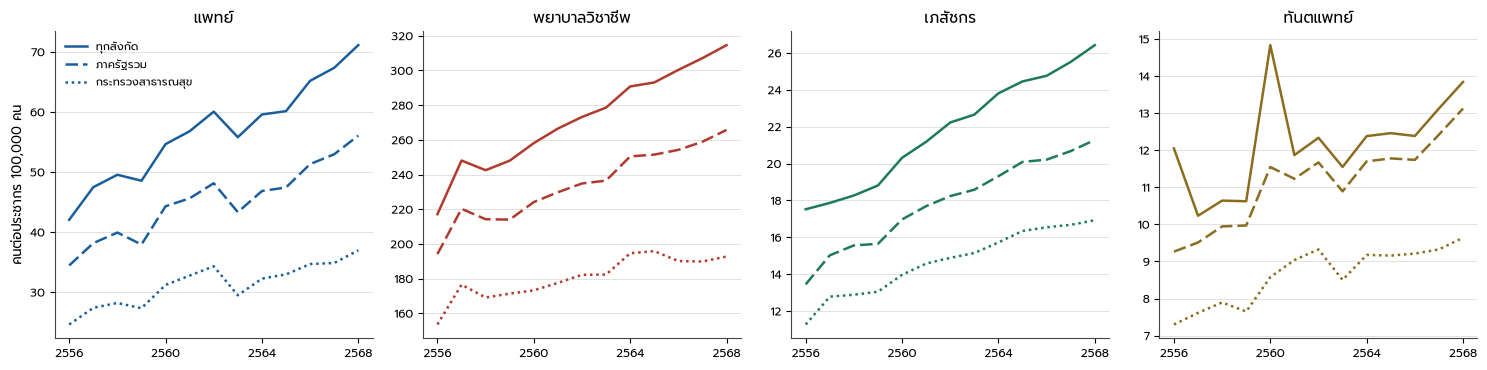

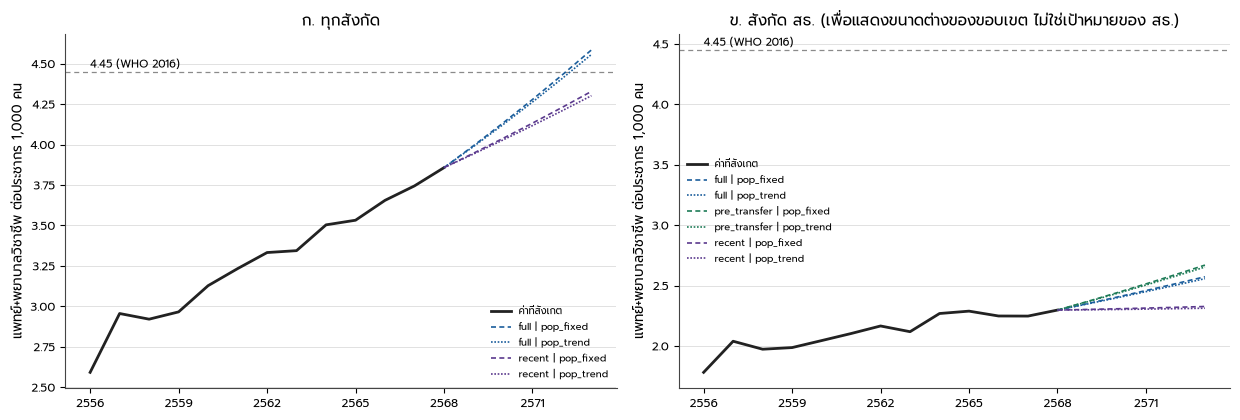

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True)
for ax, c in zip(axes, CAD):
    for u, ls in [("all_sectors", "-"), ("public_total", (0, (5, 2))), ("moph", (0, (1, 1.5)))]:
        s = DEN[(DEN.cadre == c) & (DEN.universe == u) & (DEN.register == "civil_age")]
        ax.plot(s.year, s.density_per_100k, color=R.CADRE_COLOR[c], ls=ls, lw=1.8, label=UNI_TH[u])
    ax.set_title(c); R.be_ticks(ax, C.YEARS, 4); ax.grid(**R.GRID_KW)
axes[0].set_ylabel("คนต่อประชากร 100,000 คน"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F421_DENSITY_SCOPES", fig, DEN[DEN.register == "civil_age"], "ความหนาแน่นของกำลังคนต่อประชากร 2556–2568 ตามขอบเขตบุคลากร (ตัวหารเดียวกัน)", main=True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for ax, u, title in [(axes[0], "all_sectors", "ก. ทุกสังกัด"), (axes[1], "moph", "ข. สังกัด สธ. (เพื่อแสดงขนาดต่างของขอบเขต ไม่ใช่เป้าหมายของ สธ.)")]:
    o = comb[comb.universe == u]
    ax.plot(o.year, o.density_per_1000, color="#222", lw=2, label="ค่าที่สังเกต")
    for (wn, pn), g in SCN[SCN.universe == u].groupby(["window", "population"]):
        ax.plot(g.year, g.density_per_1000, lw=1.2, ls=(0, (3, 2)) if pn == "pop_fixed" else (0, (1, 1)),
                color={"full": "#1b5e9c", "recent": "#5b3a8e", "pre_transfer": "#1e7b57"}[wn], label=f"{wn} | {pn}")
    ax.axhline(BMK, **R.REFLINE_KW); ax.annotate("4.45 (WHO 2016)", (Y0, BMK), xytext=(0, 3), textcoords="offset points", fontsize=8)
    R.be_ticks(ax, list(range(Y0, HOR + 1)), 3); ax.grid(**R.GRID_KW); ax.set_title(title)
    ax.set_ylabel("แพทย์+พยาบาลวิชาชีพ ต่อประชากร 1,000 คน"); ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
S.figure("F421_REFERENCE_SCENARIOS", fig, pd.concat([comb.assign(kind="observed"), SCN.assign(kind="scenario")]),
         "ความหนาแน่นรวมแพทย์และพยาบาลวิชาชีพ และฉากทัศน์เชิงเงื่อนไขถึงปี 2573", main=True)
plt.show()

---
# ส่วน B — 4.2.2 เทียบกับจำนวนบริการ

## B1. บริการต่อบุคลากรในขอบเขตที่จับคู่ได้
ตัวเศษคือบริการของโรงพยาบาลศูนย์/ทั่วไป/ชุมชน สธ. ตัวหารคือบุคลากรสังกัด สธ. **ของจังหวัดเดียวกัน 76 จังหวัด**
(กรุงเทพฯ มีบุคลากร สธ. ส่วนกลางและกรมวิชาการ แต่ไม่มีบริการในตารางที่ 5–7 จึงต้องตัดทั้งตัวเศษและตัวหาร)
บุคลากร สธ. ยังกว้างกว่าโรงพยาบาลกลุ่มนี้ (รวม รพ.สต. สสจ. สสอ. หน่วยกรมวิชาการ) จึงเป็น "ตัวแทนเชิงพรรณนา"
และแสดงค่าแบบรวมกรุงเทพฯ ที่ร่างเดิมใช้คู่กันเพื่อให้เห็นขนาดของความต่าง

In [9]:
wm = P.workforce_province("moph")
svm = P.services_province("moph_service", ["op_visits", "ip_days", "ip_admissions"])
rat = []
for scope, wsel, ssel in [("matched_76", wm.prov_code != BK, svm.prov_code != BK), ("national_mixed", wm.prov_code > 0, svm.prov_code > 0)]:
    w = wm[wsel].groupby(["year", "cadre"]).headcount.sum()
    s = svm[ssel].groupby(["year", "metric"]).value.sum()
    for (y, c), wv in w.items():
        for m in ["op_visits", "ip_days", "ip_admissions"]:
            rat.append(dict(scope=scope, year=y, cadre=c, metric=m, services=s[(y, m)], staff=wv,
                            per_staff=s[(y, m)] / wv, staff_per_100k_services=1e5 * wv / s[(y, m)]))
RAT = pd.DataFrame(rat)
S.table("T422_SERVICE_PER_STAFF", RAT, "บริการต่อบุคลากรหนึ่งคน และบุคลากรต่อบริการ 100,000 หน่วย (บุคลากร สธ. ÷ โรงพยาบาล สธ.)", main=True)
RS = pd.concat([M.endpoint_summary(RAT.rename(columns={"per_staff": "value"}), ["scope", "cadre", "metric"], y0=Y0, y1=Y1).assign(window="2013-2025"),
                M.endpoint_summary(RAT.rename(columns={"per_staff": "value"}), ["scope", "cadre", "metric"], y0=2018, y1=Y1).assign(window="2018-2025")])
S.table("T422_SERVICE_PER_STAFF_SUMMARY", RS, "สรุปบริการต่อบุคลากร ช่วงยาวและช่วงร่วมกับ case-mix", main=True)
display(RS[RS.cadre.isin(["แพทย์", "พยาบาลวิชาชีพ"]) & (RS.metric != "ip_admissions")].pivot_table(
    index=["cadre", "metric", "window"], columns="scope", values=["value_start", "value_end", "cagr_pct", "pct_change"]).round(2))
for _, r in RS[RS.cadre.isin(["แพทย์", "พยาบาลวิชาชีพ"])].iterrows():
    tag = f"c422_{r.scope}_{EN[r.cadre]}_{r.metric}_{r.window.replace('-', '_')}"
    S.claim(tag + "_start", r.value_start, "int", "", "T422_SERVICE_PER_STAFF_SUMMARY")
    S.claim(tag + "_end", r.value_end, "int", "")
    S.claim(tag + "_pct", r["pct_change"], "{:.2f}", "%")
    S.claim(tag + "_cagr", r.cagr_pct, "{:.2f}", "% ต่อปี")

cagr_pct                pct_change                 value_end                value_start               
scope                             matched_76 national_mixed matched_76 national_mixed matched_76 national_mixed  matched_76 national_mixed
cadre         metric    window                                                                                                            
พยาบาลวิชาชีพ ip_days   2013-2025      -0.08          -0.09      -0.91          -1.13     269.47         260.14      271.93         263.11
                        2018-2025       1.10           1.07       7.93           7.74     269.47         260.14      249.67         241.46
              op_visits 2013-2025      -0.41          -0.43      -4.86          -5.07    1120.86        1082.06     1178.13        1139.89
                        2018-2025      -0.72          -0.75      -4.94          -5.11    1120.86        1082.06     1179.07        1140.28
แพทย์         ip_days   2013-2025      -1.52          -1.57     -16.81         -17.34    1427.75        1356.13     1716.26        1640.60
                        2018-2025       0.71           0.51       5.05           3.63    1427.75        1356.13     1359.17        1308.66
              op_visits 2013-2025      -1.86          -1.91     -20.13         -20.64    5938.82        5640.92     7435.59        7107.77
                        2018-2025      -1.10          -1.30      -7.48          -8.73    5938.82        5640.92     6418.68        6180.15

## B2. ผู้ป่วยในที่ถ่วงความซับซ้อน (ปีงบประมาณ, 76 จังหวัด)
เอกลักษณ์: $\text{AdjRW}/\text{คน}=(\text{AdjRW}/\text{วันนอน})\times(\text{วันนอน}/\text{คน})$ ไม่มีการคูณวันนอนซ้ำ

In [10]:
cmp = load("casemix_province").rename(columns={"fiscal_year": "year"})
cw = cmp.groupby("year")[["sum_adjrw", "ip_days", "cases_calculated"]].sum()
cwork = []
for c in ["แพทย์", "พยาบาลวิชาชีพ"]:
    w76 = wm[(wm.prov_code != BK) & (wm.cadre == c)].groupby("year").headcount.sum()
    wnat = wm[wm.cadre == c].groupby("year").headcount.sum()
    for y in cw.index:
        cwork.append(dict(year=y, cadre=c, staff_76=w76[y], staff_national=wnat[y], sum_adjrw=cw.sum_adjrw[y],
                          drg_ip_days=cw.ip_days[y], adjrw_per_staff=cw.sum_adjrw[y] / w76[y],
                          adjrw_per_staff_national_denominator=cw.sum_adjrw[y] / wnat[y],
                          drg_days_per_staff=cw.ip_days[y] / w76[y], adjrw_per_day=cw.sum_adjrw[y] / cw.ip_days[y]))
CW = pd.DataFrame(cwork)
S.table("T422_CASEMIX_PER_STAFF", CW, "ผลรวม AdjRW และวันนอน (DRG) ต่อบุคลากร สธ. 76 จังหวัด ปีงบประมาณ 2561–2568", main=True)
display(CW.round(2))
for c in ["แพทย์", "พยาบาลวิชาชีพ"]:
    z = CW[CW.cadre == c].set_index("year")
    e = EN[c]
    S.claim(f"c422_adjrw_per_{e}_2018", z.adjrw_per_staff[2018], "{:.1f}", "AdjRW/คน/ปี", "T422_CASEMIX_PER_STAFF")
    S.claim(f"c422_adjrw_per_{e}_2025", z.adjrw_per_staff[2025], "{:.1f}", "AdjRW/คน/ปี", "T422_CASEMIX_PER_STAFF")
    S.claim(f"c422_adjrw_per_{e}_2025_natden", z.adjrw_per_staff_national_denominator[2025], "{:.1f}", "AdjRW/คน/ปี",
            note="ตัวหารรวมบุคลากร สธ. ในกรุงเทพฯ ซึ่งไม่มีตัวเศษ case-mix — ขอบเขตไม่ตรงกัน")
    S.claim(f"c422_adjrw_per_{e}_cagr", 100 * M.cagr(z.adjrw_per_staff[2018], z.adjrw_per_staff[2025], 7), "{:.2f}", "% ต่อปี")
    S.claim(f"c422_drgdays_per_{e}_cagr", 100 * M.cagr(z.drg_days_per_staff[2018], z.drg_days_per_staff[2025], 7), "{:.2f}", "% ต่อปี")
S.claim("c422_bkk_moph_physicians_2025", wm[(wm.prov_code == BK) & (wm.cadre == "แพทย์") & (wm.year == Y1)].headcount.iloc[0], "int", "คน")

,year,cadre,staff_76,staff_national,sum_adjrw,drg_ip_days,adjrw_per_staff,adjrw_per_staff_national_denominator,drg_days_per_staff,adjrw_per_day
0,2018,แพทย์,20443.0,21232.0,7908236.14,30417970,386.84,372.47,1487.94,0.26
1,2019,แพทย์,21481.0,22281.0,8183400.29,28669808,380.96,367.28,1334.66,0.29
2,2020,แพทย์,18327.0,19168.0,7993874.20,26865430,436.18,417.04,1465.89,0.30
3,2021,แพทย์,19901.0,20954.0,8211827.78,30751808,412.63,391.90,1545.24,0.27
4,2022,แพทย์,20533.0,21384.0,9179232.35,42618857,447.05,429.26,2075.63,0.22
5,2023,แพทย์,21276.0,22484.0,9611392.49,29670683,451.75,427.48,1394.56,0.32
6,2024,แพทย์,21559.0,22562.0,10441309.15,31505891,484.31,462.78,1461.38,0.33
7,2025,แพทย์,22685.0,23883.0,10979586.90,32772377,484.00,459.72,1444.67,0.34
8,2018,พยาบาลวิชาชีพ,111289.0,115074.0,7908236.14,30417970,71.06,68.72,273.32,0.26
9,2019,พยาบาลวิชาชีพ,114620.0,118319.0,8183400.29,28669808,71.40,69.16,250.13,0.29


1198.0

## B3. กิจกรรมเฉพาะวิชาชีพ: ทันตกรรมและใบสั่งยา (HDC)
ใช้เกณฑ์คัดกรองความครอบคลุมเดิมของผู้เขียน (คำนวณใหม่ทุกครั้ง): จังหวัด-ปีที่อัตรากิจกรรมต่อประชากรต่ำกว่า 10% ของมัธยฐาน
ถูกตัด และปีที่จังหวัด ≥60% เปลี่ยนเกิน ±50% พร้อมกันถูกตัดทั้งปี — พร้อมผลความไวต่อเกณฑ์

In [11]:
hdc = load("hdc_indicators")
act = hdc[hdc.indicator.isin(["dental_visits", "op_prescriptions", "pharm_ip_days"])][["year", "prov_code", "indicator", "value", "cadre"]]
pop_p = P.registers().query("register=='civil_age'")[["year", "prov_code", "population"]]
act = act.merge(pop_p, on=["year", "prov_code"], validate="many_to_one")
wmp = wm.rename(columns={"headcount": "staff"})


def screen(a, frac, yoy, share):
    a = a.sort_values(["indicator", "prov_code", "year"]).copy()
    a["rate"] = a.value / a.population
    a["covered"] = a.rate >= frac * a.groupby(["indicator", "year"]).rate.transform("median")
    a["yoy_pct"] = 100 * a.groupby(["indicator", "prov_code"]).value.pct_change()
    yr = a.dropna(subset=["yoy_pct"]).groupby(["indicator", "year"]).yoy_pct.agg(
        share_down=lambda s: (s < -yoy).mean(), share_up=lambda s: (s > yoy).mean()).reset_index()
    yr["coverage_break"] = (yr.share_down >= share) | (yr.share_up >= share)
    a = a.merge(yr[["indicator", "year", "coverage_break"]], on=["indicator", "year"], how="left")
    a["coverage_break"] = a.coverage_break.fillna(False).astype(bool)
    a["included"] = a.covered & ~a.coverage_break & a.value.notna()
    return a, yr


HS = C.CFG["hdc_screen"]
A_, YR_ = screen(act, HS["structural_noncoverage_frac"], HS["coverage_break_yoy_pct"], HS["coverage_break_share"])
A_ = A_.merge(wmp[["year", "prov_code", "cadre", "staff"]], on=["year", "prov_code", "cadre"], how="left", validate="many_to_one")
S.table("T422_HDC_SCREEN_ROWS", A_, "การคัดกรองความครอบคลุมรายจังหวัด-ปีของกิจกรรม HDC")
S.table("T422_HDC_SCREEN_YEARS", YR_, "การคัดกรองปีที่ความครอบคลุมเปลี่ยนทั้งระบบ")
S.table("T422_HDC_EXCLUDED", A_[~A_.included][["indicator", "year", "prov_code", "value", "rate", "covered", "coverage_break"]],
        "จังหวัด-ปีที่ถูกตัดออกจากอัตราส่วนกิจกรรมต่อบุคลากร พร้อมเหตุผล")
CA = (A_[A_.included].groupby(["indicator", "cadre", "year"], as_index=False)
      .agg(activity=("value", "sum"), staff=("staff", "sum"), provinces=("prov_code", "nunique")))
CA["per_staff"] = CA.activity / CA.staff
CA["per_day_240"] = CA.per_staff / C.CFG["time_scenario"]["working_days_per_year"]
S.table("T422_CADRE_ACTIVITY", CA, "กิจกรรมเฉพาะวิชาชีพต่อบุคลากร สธ. (จังหวัด-ปีที่ผ่านการคัดกรอง)", main=True)
display(CA.round(1))
# sensitivity to the screening rule
sens = []
for frac in [0.05, 0.10, 0.20]:
    for share in [0.5, 0.6, 0.7]:
        a2, _ = screen(act, frac, HS["coverage_break_yoy_pct"], share)
        a2 = a2.merge(wmp[["year", "prov_code", "cadre", "staff"]], on=["year", "prov_code", "cadre"], how="left")
        g = a2[a2.included].groupby(["indicator", "year"]).agg(activity=("value", "sum"), staff=("staff", "sum"), prov=("prov_code", "nunique"))
        for (ind, y), r in g.iterrows():
            sens.append(dict(noncoverage_frac=frac, break_share=share, indicator=ind, year=y, per_staff=r.activity / r.staff, provinces=r.prov))
S.table("T422_HDC_SCREEN_SENSITIVITY", pd.DataFrame(sens), "ความไวของกิจกรรมต่อบุคลากรต่อเกณฑ์คัดกรอง")
for ind in ["dental_visits", "op_prescriptions"]:
    z = CA[CA.indicator == ind].set_index("year")
    S.claim(f"c422_{ind}_first_year_be", C.be(z.index.min()), "{:.0f}", "พ.ศ.")
    S.claim(f"c422_{ind}_last_year_be", C.be(z.index.max()), "{:.0f}", "พ.ศ.")
    S.claim(f"c422_{ind}_first", z.per_staff.iloc[0], "int", "", "T422_CADRE_ACTIVITY")
    S.claim(f"c422_{ind}_last", z.per_staff.iloc[-1], "int", "", "T422_CADRE_ACTIVITY")
    S.claim(f"c422_{ind}_last_per_day", z.per_day_240.iloc[-1], "{:.1f}", "ต่อวัน")
S.text_claim("c422_hdc_break_years", "; ".join(f"{r.indicator} {C.be(r.year)}" for r in YR_[YR_.coverage_break].itertuples()) or "ไม่มี")

,indicator,cadre,year,activity,staff,provinces,per_staff,per_day_240
0,dental_visits,ทันตแพทย์,2022,19761734.0,5867.0,76,3368.3,14.0
1,dental_visits,ทันตแพทย์,2023,24984437.0,5860.0,75,4263.6,17.8
2,dental_visits,ทันตแพทย์,2024,25618020.0,5818.0,75,4403.2,18.3
3,dental_visits,ทันตแพทย์,2025,26019903.0,6152.0,76,4229.5,17.6
4,op_prescriptions,เภสัชกร,2022,116380926.0,10601.0,77,10978.3,45.7
5,op_prescriptions,เภสัชกร,2023,92891932.0,10724.0,77,8662.1,36.1
6,op_prescriptions,เภสัชกร,2024,98445010.0,10793.0,77,9121.2,38.0
7,pharm_ip_days,เภสัชกร,2022,38469923.0,10162.0,74,3785.7,15.8


## B4. เลขคณิตแปลงบริการเป็นเวลา: สมมติฐาน การคำนวณ และความไว

$H=(U_{OP}\,m_{OP}+A\,m_A)/60$ โดย $A$ คือผลรวม AdjRW ต่อแพทย์ และ $m_A$ คือนาทีแพทย์ต่อ 1 AdjRW **ตลอดทั้งการรับไว้รักษา**
(ไม่คูณวันนอนซ้ำ) ตัวอย่างในร่าง 30 นาที ÷ 0.3 AdjRW = **100** นาที/AdjRW ไม่ใช่ 90 จึงแสดงทั้งสองค่า

เวลาที่ได้เป็น "เวลาบริการตรง" จึงต้องเทียบกับ **งบเวลาบริการตรง** $= \text{วัน}\times\text{ชม./วัน}\times a$ (ใช้ $a$=0.6 ครั้งเดียว)
และงบนี้ต้องแบ่งระหว่าง OP, IP และงานอื่น: $H_{OP}+H_{IP}+H_{\text{อื่น}}\le \text{งบ}$ — ไม่ใช่เวลาทำงานจริงที่วัดได้

In [12]:
TS = C.CFG["time_scenario"]
ASSUMP = pd.DataFrame([
    dict(parameter="m_OP", value=TS["op_minutes_per_visit"], unit="นาทีแพทย์ต่อครั้ง OP", status="สมมติฐานประกอบภาพ",
         source="ใกล้เคียงค่าเฉลี่ย 10.7 นาทีของเวชปฏิบัติทั่วไปในหกประเทศยุโรป (Deveugele et al., BMJ 2002) — ไม่ใช่ค่าที่วัดในไทย"),
    dict(parameter="m_A (ร่างเดิม)", value=TS["adjrw_minutes_author"], unit="นาทีแพทย์ต่อ AdjRW", status="สมมติฐานประกอบภาพ", source="ร่างของผู้เขียน"),
    dict(parameter="m_A (ตามกรณีตัวอย่าง)", value=TS["adjrw_minutes_case"], unit="นาทีแพทย์ต่อ AdjRW", status="สมมติฐานประกอบภาพ",
         source="30 นาทีต่อการรับไว้ ÷ 0.3 AdjRW ตามกรณีสมมติในร่าง (ค่า AdjRW ของกรณีจริงขึ้นกับการจัดกลุ่ม ไม่ได้ตรวจกับ grouper)"),
    dict(parameter="ชั่วโมงต่อวัน", value=TS["hours_per_day"], unit="ชม.", status="สมมติฐาน", source="วันทำการปกติ"),
    dict(parameter="วันทำการต่อปี", value=TS["working_days_per_year"], unit="วัน", status="สมมติฐาน", source="ฐานเปรียบเทียบในร่าง"),
    dict(parameter="a (สัดส่วนเวลาบริการตรง)", value=TS["direct_care_share"], unit="สัดส่วน", status="สมมติฐาน", source="ร่างของผู้เขียน"),
    dict(parameter="นาทีต่อครั้งทันตกรรม", value=TS["dental_minutes_per_visit"], unit="นาที", status="สมมติฐานประกอบภาพ", source="ร่างของผู้เขียน"),
    dict(parameter="นาทีเภสัชกรต่อใบสั่งยา", value=TS["pharmacy_minutes_per_prescription"], unit="นาที", status="สมมติฐานประกอบภาพ", source="ร่างของผู้เขียน")])
S.table("T422_TIME_ASSUMPTIONS", ASSUMP, "ตารางสมมติฐานเวลา (ทุกค่าเป็นสมมติฐาน ไม่ใช่มาตรฐาน)", main=True)

phys76 = RAT[(RAT.scope == "matched_76") & (RAT.cadre == "แพทย์") & (RAT.year == Y1)].set_index("metric").per_staff
U_op = phys76["op_visits"]
A_adj = CW[(CW.cadre == "แพทย์") & (CW.year == Y1)].adjrw_per_staff.iloc[0]
budget_all = TS["working_days_per_year"] * TS["hours_per_day"]
budget_direct = budget_all * TS["direct_care_share"]
grid = []
for mop in TS["op_minutes_grid"]:
    for ma in TS["adjrw_minutes_grid"]:
        h_op, h_ip = U_op * mop / 60, A_adj * ma / 60
        H = h_op + h_ip
        grid.append(dict(m_op=mop, m_adjrw=ma, op_visits_per_physician=U_op, adjrw_per_physician=A_adj,
                         hours_op=h_op, hours_ip=h_ip, hours_total=H, days_at_8h=H / TS["hours_per_day"],
                         share_of_all_working_hours=H / budget_all, share_of_direct_care_budget=H / budget_direct,
                         working_days_needed_if_direct_share=H / TS["direct_care_share"] / TS["hours_per_day"]))
GRID = pd.DataFrame(grid)
S.table("T422_TIME_SENSITIVITY", GRID, f"เวลาบริการตรงของแพทย์ที่แปลงจากบริการที่นับได้ พ.ศ. {C.be(Y1)} (แพทย์ สธ. 76 จังหวัด) ภายใต้สมมติฐานต่าง ๆ", main=True)
display(GRID.round(2))
base = GRID[(GRID.m_op == TS["op_minutes_per_visit"]) & (GRID.m_adjrw == TS["adjrw_minutes_author"])].iloc[0]
case = GRID[(GRID.m_op == TS["op_minutes_per_visit"]) & (GRID.m_adjrw == TS["adjrw_minutes_case"])].iloc[0]
for tag, r in [("m90", base), ("m100", case)]:
    S.claim(f"c422_time_{tag}_hours_op", r.hours_op, "int", "ชม./ปี", "T422_TIME_SENSITIVITY")
    S.claim(f"c422_time_{tag}_hours_ip", r.hours_ip, "int", "ชม./ปี")
    S.claim(f"c422_time_{tag}_hours_total", r.hours_total, "int", "ชม./ปี")
    S.claim(f"c422_time_{tag}_days", r.days_at_8h, "{:.0f}", "วัน")
    S.claim(f"c422_time_{tag}_share_direct_budget", 100 * r.share_of_direct_care_budget, "{:.0f}", "%")
    S.claim(f"c422_time_{tag}_days_needed_direct_share", r.working_days_needed_if_direct_share, "{:.0f}", "วัน")
S.claim("c422_time_budget_direct_hours", budget_direct, "int", "ชม./ปี")
S.claim("c422_time_budget_all_hours", budget_all, "int", "ชม./ปี")
S.claim("c422_time_U_op", U_op, "int", "ครั้ง/แพทย์/ปี")
S.claim("c422_time_A", A_adj, "{:.1f}", "AdjRW/แพทย์/ปี")
S.claim("c422_time_grid_share_min", 100 * GRID.share_of_direct_care_budget.min(), "{:.0f}", "%")
S.claim("c422_time_grid_share_max", 100 * GRID.share_of_direct_care_budget.max(), "{:.0f}", "%")
# the draft's national-scope figures, recomputed, to show where 5,641 and 460 come from
nat_op = RAT[(RAT.scope == "national_mixed") & (RAT.cadre == "แพทย์") & (RAT.year == Y1) & (RAT.metric == "op_visits")].per_staff.iloc[0]
S.claim("c422_time_draft_op_national", nat_op, "int", "ครั้ง", note="ค่าในร่างเดิม (ตัวหารรวมบุคลากร สธ. ในกรุงเทพฯ)")
# dentistry and pharmacy: activity per day and implied hours under their own assumptions
dp = []
for ind, mins in [("dental_visits", TS["dental_minutes_per_visit"]), ("op_prescriptions", TS["pharmacy_minutes_per_prescription"])]:
    z = CA[CA.indicator == ind].sort_values("year").iloc[-1]
    dp.append(dict(indicator=ind, year=z.year, per_staff=z.per_staff, per_day=z.per_day_240, minutes=mins,
                   hours_per_day=z.per_day_240 * mins / 60, share_of_8h=z.per_day_240 * mins / 60 / TS["hours_per_day"]))
DP = pd.DataFrame(dp)
S.table("T422_DENTAL_PHARM_TIME", DP, "เวลาเทียบเท่าของกิจกรรมทันตกรรมและใบสั่งยา ภายใต้สมมติฐานของแต่ละวิชาชีพ")
for r in DP.itertuples():
    S.claim(f"c422_{r.indicator}_hours_per_day", r.hours_per_day, "{:.1f}", "ชม./วัน")

,m_op,m_adjrw,op_visits_per_physician,adjrw_per_physician,hours_op,hours_ip,hours_total,days_at_8h,share_of_all_working_hours,share_of_direct_care_budget,working_days_needed_if_direct_share
0,5.0,60.0,5938.82,484.0,494.9,484.00,978.90,122.36,0.51,0.85,203.94
1,5.0,90.0,5938.82,484.0,494.9,726.00,1220.90,152.61,0.64,1.06,254.36
2,5.0,100.0,5938.82,484.0,494.9,806.67,1301.57,162.70,0.68,1.13,271.16
3,5.0,120.0,5938.82,484.0,494.9,968.00,1462.91,182.86,0.76,1.27,304.77
4,10.0,60.0,5938.82,484.0,989.8,484.00,1473.80,184.23,0.77,1.28,307.04
5,10.0,90.0,5938.82,484.0,989.8,726.00,1715.81,214.48,0.89,1.49,357.46
6,10.0,100.0,5938.82,484.0,989.8,806.67,1796.47,224.56,0.94,1.56,374.27
7,10.0,120.0,5938.82,484.0,989.8,968.00,1957.81,244.73,1.02,1.70,407.88
8,15.0,60.0,5938.82,484.0,1484.7,484.00,1968.71,246.09,1.03,1.71,410.15
9,15.0,90.0,5938.82,484.0,1484.7,726.00,2210.71,276.34,1.15,1.92,460.56


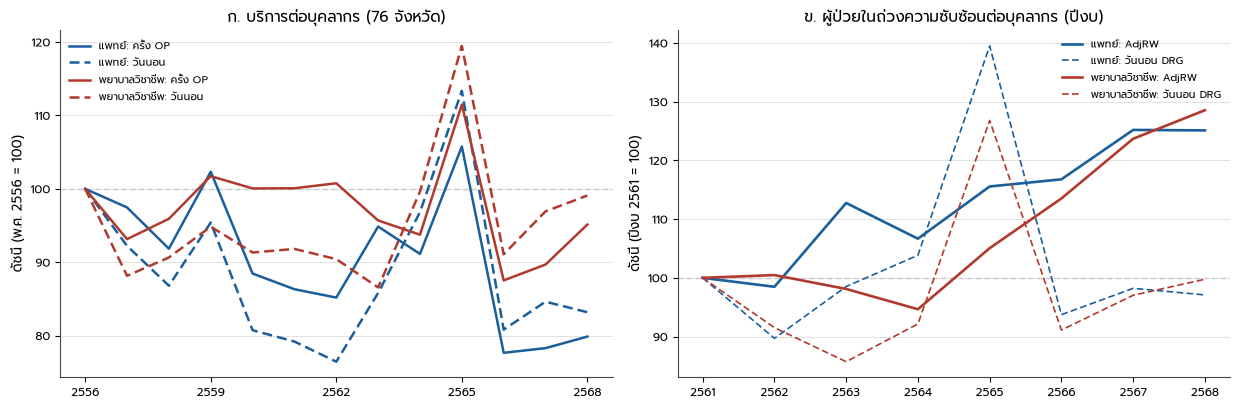

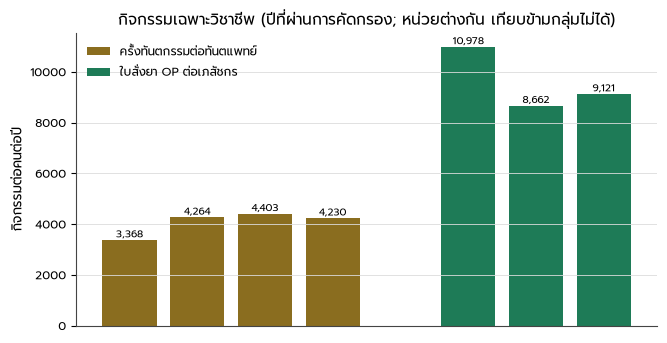

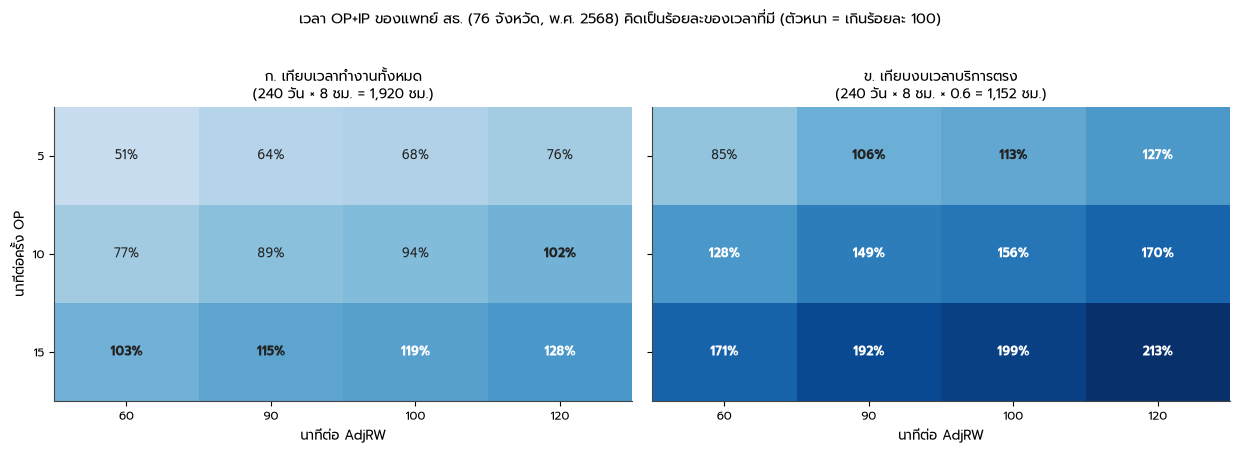

93.56630169646792

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
for (c, m), col, ls in [(("แพทย์", "op_visits"), "#1b5e9c", "-"), (("แพทย์", "ip_days"), "#1b5e9c", (0, (4, 2))),
                        (("พยาบาลวิชาชีพ", "op_visits"), "#b03a2e", "-"), (("พยาบาลวิชาชีพ", "ip_days"), "#b03a2e", (0, (4, 2)))]:
    z = RAT[(RAT.scope == "matched_76") & (RAT.cadre == c) & (RAT.metric == m)]
    ax.plot(z.year, 100 * z.per_staff / z.per_staff.iloc[0], color=col, ls=ls, lw=1.8, label=f"{c}: {'ครั้ง OP' if m == 'op_visits' else 'วันนอน'}")
ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, C.YEARS, 3); ax.grid(**R.GRID_KW)
ax.set_title("ก. บริการต่อบุคลากร (76 จังหวัด)"); ax.set_ylabel(f"ดัชนี (พ.ศ. {C.be(Y0)} = 100)"); ax.legend(frameon=False, fontsize=7.5)
ax = axes[1]
for c, col in [("แพทย์", "#1b5e9c"), ("พยาบาลวิชาชีพ", "#b03a2e")]:
    z = CW[CW.cadre == c]
    ax.plot(z.year, 100 * z.adjrw_per_staff / z.adjrw_per_staff.iloc[0], color=col, lw=1.9, label=f"{c}: AdjRW")
    ax.plot(z.year, 100 * z.drg_days_per_staff / z.drg_days_per_staff.iloc[0], color=col, lw=1.2, ls=(0, (4, 2)), label=f"{c}: วันนอน DRG")
ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, list(range(2018, 2026)), 1); ax.grid(**R.GRID_KW)
ax.set_title("ข. ผู้ป่วยในถ่วงความซับซ้อนต่อบุคลากร (ปีงบ)"); ax.set_ylabel("ดัชนี (ปีงบ 2561 = 100)"); ax.legend(frameon=False, fontsize=7.5)
fig.tight_layout()
S.figure("F422_SERVICE_PER_STAFF_TIME", fig, pd.concat([RAT.assign(panel="A"), CW.assign(panel="B")]),
         "บริการต่อบุคลากร และผู้ป่วยในถ่วงความซับซ้อนต่อบุคลากร", main=True)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = 0
for ind, col, lab in [("dental_visits", R.CADRE_COLOR["ทันตแพทย์"], "ครั้งทันตกรรมต่อทันตแพทย์"), ("op_prescriptions", R.CADRE_COLOR["เภสัชกร"], "ใบสั่งยา OP ต่อเภสัชกร")]:
    z = CA[CA.indicator == ind]
    xs = np.arange(len(z)) + x
    ax.bar(xs, z.per_staff, color=col, label=lab)
    for xx, v, y in zip(xs, z.per_staff, z.year):
        ax.annotate(f"{v:,.0f}", (xx, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7.5)
    x += len(z) + 1
ax.set_xticks([]); ax.set_ylabel("กิจกรรมต่อคนต่อปี"); ax.legend(frameon=False); ax.grid(**R.GRID_KW)
ax.set_title("กิจกรรมเฉพาะวิชาชีพ (ปีที่ผ่านการคัดกรอง; หน่วยต่างกัน เทียบข้ามกลุ่มไม่ได้)")
S.figure("F422_DENTAL_PHARM", fig, CA, "กิจกรรมเฉพาะวิชาชีพต่อบุคลากร สธ. พ.ศ. 2565–2568", main=True)
plt.show()

# ---- time-budget sensitivity: all working hours (no x0.6) vs the direct-care budget (x0.6), one colour scale
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
panels = [("share_of_all_working_hours", f"ก. เทียบเวลาทำงานทั้งหมด\n({TS['working_days_per_year']} วัน × {TS['hours_per_day']:.0f} ชม. = {budget_all:,.0f} ชม.)"),
          ("share_of_direct_care_budget", f"ข. เทียบงบเวลาบริการตรง\n({TS['working_days_per_year']} วัน × {TS['hours_per_day']:.0f} ชม. × {TS['direct_care_share']} = {budget_direct:,.0f} ชม.)")]
vmax = 100 * GRID.share_of_direct_care_budget.max()
for ax, (col, title) in zip(axes, panels):
    piv = GRID.pivot(index="m_op", columns="m_adjrw", values=col)
    ax.imshow(100 * piv.values, cmap="Blues", aspect="auto", vmin=0, vmax=vmax)
    for r_ in range(piv.shape[0]):
        for c_ in range(piv.shape[1]):
            v = 100 * piv.values[r_, c_]
            ax.text(c_, r_, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if v > 0.55 * vmax else "#222",
                    fontweight="bold" if v > 100 else "normal")
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"{v:.0f}" for v in piv.columns]); ax.set_xlabel("นาทีต่อ AdjRW")
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([f"{v:.0f}" for v in piv.index])
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("นาทีต่อครั้ง OP")
fig.suptitle(f"เวลา OP+IP ของแพทย์ สธ. (76 จังหวัด, พ.ศ. {C.be(Y1)}) คิดเป็นร้อยละของเวลาที่มี (ตัวหนา = เกินร้อยละ 100)", fontsize=10.5, y=1.02)
fig.tight_layout()
S.figure("F422_TIME_BUDGET", fig, GRID, f"เวลาผู้ป่วยนอกและผู้ป่วยในของแพทย์ที่แปลงจากบริการที่นับได้ เทียบเวลาทำงานทั้งหมด และเทียบงบเวลาบริการตรง (ร้อยละ 60) ภายใต้สมมติฐานเวลาต่าง ๆ", main=True)
plt.show()
S.claim("c422_time_grid_allhours_min", 100 * GRID.share_of_all_working_hours.min(), "{:.0f}", "%")
S.claim("c422_time_grid_allhours_max", 100 * GRID.share_of_all_working_hours.max(), "{:.0f}", "%")
S.claim("c422_time_m100_share_all_hours", 100 * case.share_of_all_working_hours, "{:.0f}", "%")

---
# ส่วน C — 4.2.3 หรือเทียบกับความจำเป็น

## C1. ตัวอย่างร่วม (common complete-case panel)
ตัดกรุงเทพฯ ก่อนสร้างตัวอย่าง ใช้ปีที่มีความชุกโรคจริง 2565–2568 และใช้แถวชุดเดียวกันสำหรับ M0–M5 และทั้งสามผลลัพธ์
ความชุกอยู่ในหน่วยร้อยละ (ตรวจแล้วว่า = 100×ผู้ป่วย/ประชากรฐานของตัวชี้วัด)

In [14]:
panel, joins = P.province_panel()
Z = panel[panel.elig_m5_common].reset_index(drop=True)
EXCL = P.m5_exclusions(panel)
S.table("T423_SAMPLE_EXCLUSIONS", EXCL, "จังหวัด-ปีที่ไม่อยู่ในตัวอย่างร่วม และตัวแปรที่ขาด")
S.table("T423_SAMPLE_ROWS", Z[["prov_code", "province", "year"]], "รายการจังหวัด-ปีในตัวอย่างร่วมของ M0–M5")
S.claim("c423_n_rows", len(Z), "int", "จังหวัด-ปี")
S.claim("c423_n_prov", Z.prov_code.nunique(), "int", "จังหวัด")
S.claim("c423_n_excluded", len(EXCL), "int", "จังหวัด-ปี")
S.text_claim("c423_excluded_list", "; ".join(f"{r.province} {C.be(r.year)} ({r.missing_fields})" for r in EXCL.itertuples()))
desc_cols = ["op_moph_pc", "ip_moph_pc", "adjrw_pc", "s3_0-14", "s3_60+"] + P.DISEASE + ["gpp_lag1", "log_beds_moph_per1000", "log_beds_cmx_per1000",
             "log_moph_physicians_per100k", "log_moph_professional_nurses_per100k"]
DESC = Z[desc_cols].describe().T.reset_index().rename(columns={"index": "variable"})
S.table("T423_SAMPLE_DESCRIPTIVES", DESC, "ค่าสถิติพรรณนาของตัวแปรในตัวอย่างร่วม (หน่วย: ครั้ง/วัน/AdjRW ต่อคน; สัดส่วน; ร้อยละ; log)")
display(DESC.round(3))

,variable,count,mean,std,min,25%,50%,75%,max
0,op_moph_pc,302.0,2.421,0.610,1.008,2.016,2.376,2.767,4.719
1,ip_moph_pc,302.0,0.580,0.143,0.221,0.505,0.561,0.628,1.211
2,adjrw_pc,302.0,0.170,0.041,0.067,0.145,0.170,0.194,0.326
3,s3_0-14,302.0,0.152,0.026,0.103,0.138,0.148,0.159,0.253
4,s3_60+,302.0,0.206,0.037,0.124,0.181,0.204,0.229,0.306
5,prev_dm,302.0,8.007,1.736,3.576,6.934,8.053,9.298,12.057
6,prev_ht,302.0,16.711,4.122,8.964,13.399,16.224,19.658,28.107
7,prev_ckd_3_5,302.0,1.156,0.402,0.445,0.890,1.089,1.406,2.469
8,prev_copd,302.0,0.437,0.178,0.121,0.299,0.413,0.565,0.887
9,prev_stroke,302.0,0.700,0.538,0.028,0.274,0.576,0.983,2.550


## C2. M0–M5 และการตรวจสอบนอกตัวอย่างแบบแบ่งตามจังหวัด

| แบบจำลอง | เพิ่มจากแบบก่อนหน้า |
|---|---|
| M0 | ค่าคงที่ + ตัวแปรหุ่นปี |
| M1 | สัดส่วนอายุ 0–14 และ 60+ (15–59 เป็นกลุ่มอ้างอิง) |
| M2 | ความชุกที่บันทึก: เบาหวาน ความดัน ไตเรื้อรังระยะ 3–5 ปอดอุดกั้น หลอดเลือดสมอง หลอดเลือดหัวใจ |
| M3 | log GPP ต่อหัวของปีก่อน |
| M4 | log เตียงต่อประชากร 1,000 (โรงพยาบาล สธ. สำหรับ OP/วันนอน; เตียงในชุด case-mix สำหรับ AdjRW) |
| M5 | log แพทย์ **และ** log พยาบาลวิชาชีพ ต่อประชากร 100,000 (สังกัด สธ.) คงเตียงไว้ |

$R^2_{pred}=1-\sum(y-\hat y)^2/\sum(y-\bar y_{train})^2$ รวมทุกรอบและทุก fold; 5 folds × 10 รอบ แบ่งตามจังหวัด; seed ตาม config

In [15]:
BLOCKS = {"M0": [], "M1": ["age"], "M2": ["age", "disease"], "M3": ["age", "disease", "gpp"],
          "M4": ["age", "disease", "gpp", "beds"], "M5": ["age", "disease", "gpp", "beds", "physicians", "nurses"]}
FULL = BLOCKS["M5"]
ABL = {"M5_no_age": [b for b in FULL if b != "age"], "M5_no_disease": [b for b in FULL if b != "disease"],
       "M5_no_gpp": [b for b in FULL if b != "gpp"], "M5_no_beds": [b for b in FULL if b != "beds"],
       "M5_no_physicians": [b for b in FULL if b != "physicians"], "M5_no_nurses": [b for b in FULL if b != "nurses"],
       "M5_no_workforce(=M4)": BLOCKS["M4"], "M1_plus_supply": ["age", "beds", "physicians", "nurses"]}
MC = C.CFG["models"]
OUT = MC["outcomes"]
OUT_TH = {"op_moph": "ครั้งผู้ป่วยนอก", "ip_moph": "วันนอนรวม", "adjrw": "ผลรวม AdjRW"}
FOLDS = MD.province_folds(Z.prov_code.unique(), MC["cv_folds"], MC["cv_repeats"], MC["cv_seed"])
S.table("T423_FOLD_ASSIGNMENT", FOLDS, "การแบ่ง fold ตามจังหวัด (ใช้ชุดเดียวกันทุกแบบจำลองและทุกผลลัพธ์)")
preds = []
for o in OUT:
    preds.append(MD.cross_validate(Z, o, {**BLOCKS, **ABL}, FOLDS, age_k=3))
    six = {m: b for m, b in BLOCKS.items()}
    preds.append(MD.cross_validate(Z, o, six, FOLDS, age_k=6))
    pp = MD.cross_validate(Z, o, BLOCKS, FOLDS, age_k=3, positive=True, repeats=MC["positive_model_repeats"])
    print(o, "positive-model convergence failures:", pp.attrs["convergence_failures"])
    preds.append(pp)
PRED = pd.concat(preds, ignore_index=True)
S.table("T423_OOF_PREDICTIONS", PRED, "ค่าทำนายนอก fold ทุกแถว ทุกรอบ (รวมค่าเฉลี่ยชุดฝึกที่ใช้เป็นฐาน)")
SC = MD.score(PRED)
S.table("T423_MODEL_VALIDATION", SC, "ความสามารถในการทำนายบริการของ M0–M5 และแบบถอดตัวแปร (R² ตามนิยามฐานค่าเฉลี่ยชุดฝึก)", main=True)
main_sc = SC[(SC.estimator == "ols") & (SC.age_groups == 3) & SC.model.isin(BLOCKS)]
display(main_sc.pivot(index="model", columns="outcome", values="r2_pred_train_mean").round(3))
display(SC[(SC.estimator == "ols") & (SC.age_groups == 3) & ~SC.model.isin(BLOCKS)].pivot(index="model", columns="outcome", values="r2_pred_train_mean").round(3))
for r in SC.itertuples():
    tag = f"{r.outcome}_{r.model}_{r.estimator}_{r.age_groups}".replace("(", "").replace(")", "").replace("=", "_")
    S.claim(f"c423_r2_{tag}", r.r2_pred_train_mean, "{:.3f}", "", "T423_MODEL_VALIDATION")
    S.claim(f"c423_mae_{tag}", r.mae, "{:.3f}", "")
PAIRS = [("M0", "M1"), ("M1", "M2"), ("M2", "M3"), ("M3", "M4"), ("M4", "M5"), ("M3", "M5"), ("M0", "M5")] + [(m, "M5") for m in ABL if m != "M1_plus_supply"] + [("M1_plus_supply", "M5"), ("M0", "M1_plus_supply")]
GAINS = MD.paired_gains(PRED, PAIRS, MC["paired_bootstrap_draws"], MC["cv_seed"] + 991)
S.table("T423_PAIRED_GAINS", GAINS, "การลดลงของผลรวมความคลาดเคลื่อนกำลังสองนอกตัวอย่าง (%) พร้อมช่วง 95% จาก bootstrap จังหวัด", main=True)
g3 = GAINS[(GAINS.estimator == "ols") & (GAINS.age_groups == 3)]
display(g3.pivot_table(index=["baseline", "model"], columns="outcome", values=["sse_reduction_pct", "lo95", "hi95"]).round(2))
for r in GAINS.itertuples():
    tag = f"{r.outcome}_{r.baseline}_{r.model}_{r.estimator}_{r.age_groups}".replace("(", "").replace(")", "").replace("=", "_")
    S.claim(f"c423_gain_{tag}", r.sse_reduction_pct, "{:.2f}", "%", "T423_PAIRED_GAINS")
    S.claim(f"c423_gainlo_{tag}", r.lo95, "{:.2f}", "%")
    S.claim(f"c423_gainhi_{tag}", r.hi95, "{:.2f}", "%")

# best specification by predictive R2 (primary OLS, three groups), including ablations
best = SC[(SC.estimator == "ols") & (SC.age_groups == 3)].sort_values("r2_pred_train_mean", ascending=False).groupby("outcome").head(1)
for r in best.itertuples():
    S.text_claim(f"c423_best_model_{r.outcome}", r.model)

op_moph positive-model convergence failures: 0
ip_moph positive-model convergence failures: 0


adjrw positive-model convergence failures: 0


outcome,adjrw,ip_moph,op_moph
model,,,
M0,0.073,0.245,0.182
M1,0.013,0.282,0.301
M2,0.190,0.312,0.263
M3,0.179,0.326,0.254
M4,0.356,0.587,0.450
M5,0.511,0.592,0.462


outcome,adjrw,ip_moph,op_moph
model,,,
M1_plus_supply,0.504,0.596,0.512
M5_no_age,0.521,0.575,0.494
M5_no_beds,0.478,0.489,0.442
M5_no_disease,0.501,0.595,0.503
M5_no_gpp,0.535,0.591,0.472
M5_no_nurses,0.515,0.594,0.467
M5_no_physicians,0.345,0.584,0.463
M5_no_workforce(=M4),0.356,0.587,0.450


hi95                   lo95                 sse_reduction_pct                
outcome                              adjrw ip_moph op_moph  adjrw ip_moph op_moph             adjrw ip_moph op_moph
baseline             model                                                                                         
M0                   M1               6.05   16.47   27.06 -20.96  -11.19   -2.03             -6.50    4.86   14.53
                     M1_plus_supply  61.90   59.26   53.17  26.59   30.66   23.90             46.54   46.53   40.32
                     M5              63.03   58.03   49.19  24.91   31.24   14.90             47.22   46.01   34.25
M1                   M2              38.75   15.24    4.30 -11.79   -9.62  -15.45             17.95    4.24   -5.42
M1_plus_supply       M5              20.13    3.76   -0.11 -25.97   -7.46  -21.55              1.26   -0.97  -10.17
M2                   M3               2.89    6.47    1.89  -7.64   -3.26   -4.57             -1.40    2.03   -1.15
M3                   M4              35.50   49.01   38.49   6.70   27.56   10.40             21.63   38.68   26.20
                     M5              55.10   50.18   40.26  21.81   27.76   12.37             40.43   39.51   27.86
M4                   M5              40.93    5.89   11.74   4.61   -2.52   -9.40             23.98    1.35    2.24
M5_no_age            M5               8.99    8.25    2.74 -15.79   -1.00  -18.70             -2.22    4.05   -6.42
M5_no_beds           M5              17.53   29.40   10.90  -7.59   11.54   -4.68              6.27   20.17    3.56
M5_no_disease        M5              18.94    3.80    1.55 -24.97   -6.41  -19.56              2.03   -0.56   -8.34
M5_no_gpp            M5              -1.06    2.57   -0.96  -9.06   -2.80   -3.04             -5.16    0.23   -1.91
M5_no_nurses         M5               2.67    0.57    3.57  -5.31   -1.60   -5.99             -0.99   -0.50   -0.93
M5_no_physicians     M5              38.24    6.05    3.82  11.37   -1.74   -4.46             25.28    1.90   -0.18
M5_no_workforce(=M4) M5              40.93    5.89   11.74   4.61   -2.52   -9.40             23.98    1.35    2.24

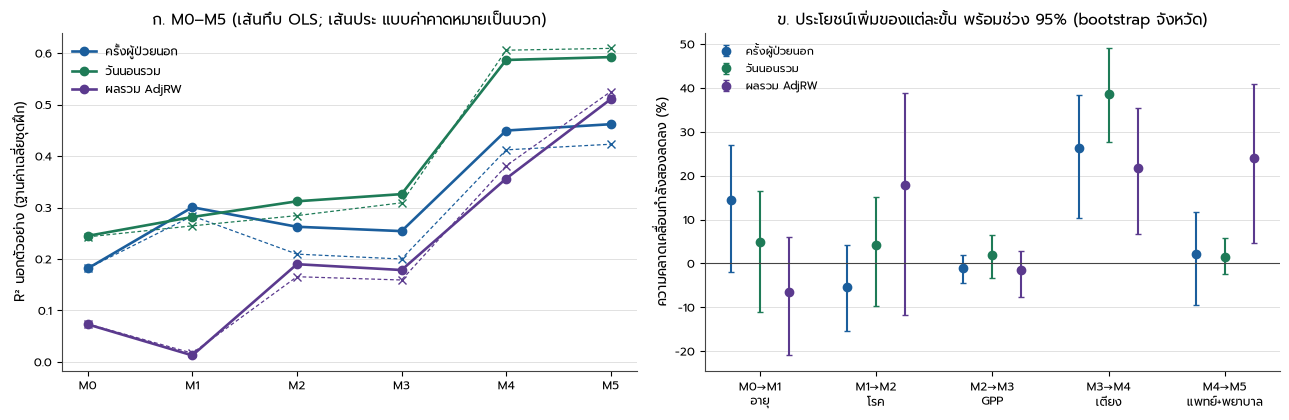

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for o, col in zip(OUT, ["#1b5e9c", "#1e7b57", "#5b3a8e"]):
    z = main_sc[main_sc.outcome == o].set_index("model").reindex(list(BLOCKS))
    ax.plot(range(6), z.r2_pred_train_mean, marker="o", color=col, lw=1.9, label=OUT_TH[o])
    zp = SC[(SC.estimator != "ols") & (SC.outcome == o)].set_index("model").reindex(list(BLOCKS))
    ax.plot(range(6), zp.r2_pred_train_mean, marker="x", color=col, lw=0.9, ls=(0, (3, 2)))
ax.set_xticks(range(6)); ax.set_xticklabels(list(BLOCKS)); ax.set_ylabel("R² นอกตัวอย่าง (ฐานค่าเฉลี่ยชุดฝึก)")
ax.set_title("ก. M0–M5 (เส้นทึบ OLS; เส้นประ แบบค่าคาดหมายเป็นบวก)"); ax.legend(frameon=False); ax.grid(**R.GRID_KW)
ax = axes[1]
pl = g3[g3.baseline.isin(["M0", "M1", "M2", "M3", "M4"]) & (g3.model == g3.baseline.map({"M0": "M1", "M1": "M2", "M2": "M3", "M3": "M4", "M4": "M5"}))]
for i, o in enumerate(OUT):
    z = pl[pl.outcome == o].reset_index(drop=True)
    xs = np.arange(len(z)) + (i - 1) * 0.25
    ax.errorbar(xs, z.sse_reduction_pct, yerr=[z.sse_reduction_pct - z.lo95, z.hi95 - z.sse_reduction_pct], fmt="o",
                color=["#1b5e9c", "#1e7b57", "#5b3a8e"][i], capsize=2, label=OUT_TH[o])
ax.axhline(0, color="#444", lw=0.8)
ax.set_xticks(range(5)); ax.set_xticklabels(["M0→M1\nอายุ", "M1→M2\nโรค", "M2→M3\nGPP", "M3→M4\nเตียง", "M4→M5\nแพทย์+พยาบาล"])
ax.set_ylabel("ความคลาดเคลื่อนกำลังสองลดลง (%)"); ax.set_title("ข. ประโยชน์เพิ่มของแต่ละขั้น พร้อมช่วง 95% (bootstrap จังหวัด)")
ax.legend(frameon=False, fontsize=8); ax.grid(**R.GRID_KW)
fig.tight_layout()
S.figure("F423_MODEL_VALIDATION", fig, pd.concat([main_sc.assign(panel="A"), pl.assign(panel="B")]),
         "ความสามารถในการทำนายบริการนอกตัวอย่างของ M0–M5 และประโยชน์เพิ่มของแต่ละขั้น", main=True)
plt.show()

### ตรวจการสร้างซ้ำ: ตารางที่ 1 ในร่างเดิม
ร่างเดิมแบ่ง fold จากรายชื่อจังหวัดที่เรียงตามชื่อภาษาไทย ส่วนงานนี้เรียงตามรหัสจังหวัด (seed เดียวกัน) จึงได้กลุ่มจังหวัดคนละชุด
ด้านล่างสร้าง fold แบบเดิมเพื่อยืนยันว่าความต่างของ R² มาจากการแบ่ง fold เท่านั้น — ค่าในร่างใช้เป็น **ค่าเทียบ** ไม่ใช่ผลลัพธ์

In [17]:
from sklearn.model_selection import KFold
_names = Z.drop_duplicates("prov_code").set_index("province").prov_code
_pn = np.array(sorted(_names.index))
_fr = []
for r in range(MC["cv_repeats"]):
    for f, (_, te) in enumerate(KFold(MC["cv_folds"], shuffle=True, random_state=MC["cv_seed"] + r).split(_pn)):
        _fr += [dict(repeat=r, prov_code=int(_names[p]), fold=f) for p in _pn[te]]
FOLDS_NAME = pd.DataFrame(_fr)
REPRO = MD.score(pd.concat([MD.cross_validate(Z, o, BLOCKS, FOLDS_NAME) for o in OUT]))
DRAFT_T1 = {("op_moph", "M0"): 0.181, ("op_moph", "M1"): 0.327, ("op_moph", "M2"): 0.300, ("op_moph", "M3"): 0.292, ("op_moph", "M4"): 0.463, ("op_moph", "M5"): 0.469,
            ("ip_moph", "M0"): 0.245, ("ip_moph", "M1"): 0.290, ("ip_moph", "M2"): 0.330, ("ip_moph", "M3"): 0.350, ("ip_moph", "M4"): 0.590, ("ip_moph", "M5"): 0.597,
            ("adjrw", "M0"): 0.073, ("adjrw", "M1"): 0.070, ("adjrw", "M2"): 0.210, ("adjrw", "M3"): 0.207, ("adjrw", "M4"): 0.363, ("adjrw", "M5"): 0.506}
REPRO["draft_table1_r2"] = [DRAFT_T1[(o, m)] for o, m in zip(REPRO.outcome, REPRO.model)]
REPRO["abs_diff_3dp"] = (REPRO.r2_pred_train_mean.round(3) - REPRO.draft_table1_r2).abs()
REPRO = REPRO.merge(main_sc[["outcome", "model", "r2_pred_train_mean"]].rename(columns={"r2_pred_train_mean": "r2_code_ordered_folds"}), on=["outcome", "model"])
S.table("T423_REPRODUCTION_CHECK", REPRO[["outcome", "model", "draft_table1_r2", "r2_pred_train_mean", "abs_diff_3dp", "r2_code_ordered_folds"]],
        "สร้างตารางที่ 1 ของร่างซ้ำด้วยการแบ่ง fold แบบเดิม และเทียบกับการแบ่ง fold ของงานนี้")
display(REPRO[["outcome", "model", "draft_table1_r2", "r2_pred_train_mean", "abs_diff_3dp", "r2_code_ordered_folds"]].round(3))
S.claim("c423_repro_max_absdiff", REPRO.abs_diff_3dp.max(), "{:.3f}", "")
S.claim("c423_fold_order_max_r2_shift", (REPRO.r2_pred_train_mean - REPRO.r2_code_ordered_folds).abs().max(), "{:.3f}", "")

,outcome,model,draft_table1_r2,r2_pred_train_mean,abs_diff_3dp,r2_code_ordered_folds
0,adjrw,M0,0.073,0.073,0.0,0.073
1,adjrw,M1,0.070,0.070,0.0,0.013
2,adjrw,M2,0.210,0.210,0.0,0.190
3,adjrw,M3,0.207,0.207,0.0,0.179
4,adjrw,M4,0.363,0.363,0.0,0.356
5,adjrw,M5,0.506,0.506,0.0,0.511
6,ip_moph,M0,0.245,0.245,0.0,0.245
7,ip_moph,M1,0.290,0.290,0.0,0.282
8,ip_moph,M2,0.330,0.330,0.0,0.312
9,ip_moph,M3,0.350,0.350,0.0,0.326


0.057521377872290946

## C3. ทำนายปีถัดไปได้หรือไม่ (temporal validation)
ตัวแปรหุ่นปีของปีที่ไม่อยู่ในชุดฝึกประมาณไม่ได้ จึงใช้สองกฎเดียวกันทุกแบบจำลอง: แนวโน้มเวลาเชิงเส้น หรือใช้ผลของปีสุดท้ายในชุดฝึก
และแยก (ก) *conditional retrospective* ที่ใช้ตัวแปรของปีทดสอบเอง กับ (ข) *forward* ที่ใช้ค่าตัวแปรของปีสุดท้ายก่อนปีทดสอบ
เทียบกับฐาน "ใช้อัตราบริการปีก่อนของจังหวัดเดิม" (persistence)

In [18]:
TMP = []
for o in OUT:
    for ty, prior in [(2025, [2022, 2023, 2024]), (2024, [2022, 2023])]:
        TMP.append(MD.temporal_validation(Z, o, BLOCKS, ty, prior))
TMP = pd.concat(TMP, ignore_index=True)
TSC = MD.score_temporal(TMP)
S.table("T423_TEMPORAL_PREDICTIONS", TMP, "ค่าทำนายปีถัดไป (ทุกกฎและชุดข้อมูล)")
S.table("T423_TEMPORAL_VALIDATION", TSC, "ความสามารถทำนายปีถัดไป เทียบฐาน persistence", main=True)
display(TSC[(TSC.test_year == 2025)].pivot_table(index=["information", "year_rule", "model"], columns="outcome", values="r2_pred_train_mean").round(3))
for o in OUT:
    t = TSC[(TSC.outcome == o) & (TSC.test_year == 2025)]
    pers = t[t.model == "persistence"].rmse.iloc[0]
    best_model = t[t.model != "persistence"].rmse.min()
    S.claim(f"c423_temporal_{o}_persistence_rmse", pers, "{:.4f}", "")
    S.claim(f"c423_temporal_{o}_best_model_rmse", best_model, "{:.4f}", "")
    S.text_claim(f"c423_temporal_{o}_persistence_wins", "ใช่" if pers < best_model else "ไม่ใช่")
    S.claim(f"c423_temporal_{o}_m5_forward_r2", t[(t.model == "M5") & (t.information == "forward") & (t.year_rule == "last_year_effect")].r2_pred_train_mean.iloc[0], "{:.3f}", "")
    S.claim(f"c423_temporal_{o}_persist_r2", t[(t.model == "persistence") & (t.information == "forward")].r2_pred_train_mean.iloc[0], "{:.3f}", "")

outcome                                                 adjrw  ip_moph  op_moph
information               year_rule        model                               
conditional_retrospective last_year_effect M0           0.147    0.040   -0.113
                                           M1           0.205    0.117    0.171
                                           M2           0.440    0.219    0.183
                                           M3           0.454    0.137    0.197
                                           M4           0.553    0.378    0.345
                                           M5           0.693    0.414    0.409
                          none             persistence  0.946    0.804    0.673
                          trend            M0           0.179   -1.936   -1.229
                                           M1           0.220   -1.885   -0.995
                                           M2           0.457   -1.713   -1.003
                                           M3           0.466   -1.820   -0.997
                                           M4           0.564   -1.638   -0.867
                                           M5           0.696   -1.582   -0.703
forward                   last_year_effect M0           0.147    0.040   -0.113
                                           M1           0.188    0.101    0.117
                                           M2           0.425    0.210    0.153
                                           M3           0.432    0.108    0.160
                                           M4           0.536    0.334    0.328
                                           M5           0.670    0.360    0.381
                          none             persistence  0.946    0.804    0.673
                          trend            M0           0.179   -1.936   -1.229
                                           M1           0.219   -2.002   -1.241
                                           M2           0.456   -1.757   -1.155
                                           M3           0.461   -2.035   -1.169
                                           M4           0.566   -1.752   -0.974
                                           M5           0.695   -1.754   -0.848

## C4. บริการสัมพันธ์กับอุปทานอย่างไร — และข้อมูลนี้บอกเรื่อง supplier-induced demand ได้แค่ไหน

ใช้ PPML: $\log E[V_{pt}]=\log P_{pt}+\alpha+\delta_t(+\alpha_p)+\theta_B\log(B/P)+\theta_M\log(M/P)+\theta_N\log(N/P)+\dots$
สัมประสิทธิ์ของ log ความหนาแน่นเป็น elasticity; รายงาน % ที่เปลี่ยนเมื่อความหนาแน่นสูงขึ้น 10% $=100(1.1^\beta-1)$
(ช่วงความเชื่อมั่นแปลงด้วยสูตรเดียวกัน) inference แบบ cluster จังหวัด
* **ระหว่างจังหวัด+ภายใน** (pooled, year FE) และ **ภายในจังหวัด** (province + year FE)
* แผงยาว (ตัวแปรที่มีตลอด 2556–2568; AdjRW 2561–2568) เทียบแผงสั้นที่ปรับโรคแล้ว 2565–2568
* แบบร่วมสามตัวแปร และแบบลดรูปทีละตัว; ความไวต่ออุปทานปีก่อน (join ปีตรงตัว)

In [19]:
LP = panel.copy()
for c in ["log_beds_moph_per1000", "log_beds_cmx_per1000", "log_moph_physicians_per100k", "log_moph_professional_nurses_per100k"]:
    lag = LP[["prov_code", "year", c]].assign(year=lambda d: d.year + 1).rename(columns={c: c + "_lag1"})
    LP = LP.merge(lag, on=["prov_code", "year"], how="left", validate="one_to_one")
SUP = {"beds": None, "physicians": MD.PHYS, "nurses": MD.NURS}
assoc, diag = [], []
for o in OUT:
    bed = MD.BED_COL[o]
    first = MC["supply_long_first"] if o != "adjrw" else C.CFG["years"]["casemix_first"]
    long_ = LP[(LP.year >= first) & np.isfinite(LP[MD.RATE_COL[o]])]
    short = LP[LP.elig_m5_common]
    ctrl_long = ["s3_0-14", "s3_60+", "log_gpp_lag1"]
    ctrl_short = ctrl_long + P.DISEASE
    specs = {"joint": [bed, MD.PHYS, MD.NURS], "beds_only": [bed], "physicians_only": [MD.PHYS], "nurses_only": [MD.NURS],
             "workforce_only": [MD.PHYS, MD.NURS]}
    for panel_name, data, ctrl in [("long", long_, ctrl_long), ("short_morbidity", short, ctrl_short)]:
        for spec, xs in specs.items():
            for fe_name, fe in [("pooled_year_fe", ["year"]), ("province_year_fe", ["year", "prov_code"])]:
                res = MD.ppml(data, MD.TOTAL_COL[o], xs + ctrl, "population", fe, "prov_code")
                t = res["table"]
                t = t[t.term.isin(xs)].assign(outcome=o, panel=panel_name, spec=spec, fe=fe_name, n=res["n"],
                                               provinces=res["clusters"], years=f"{data.year.min()}-{data.year.max()}")
                assoc.append(t)
                diag.append(dict(outcome=o, panel=panel_name, spec=spec, fe=fe_name, n=res["n"], converged=res["converged"],
                                 separated=len(res["separated_groups"]), pearson_dispersion=res["pearson_dispersion"]))
        if panel_name == "long":
            xs = [bed + "_lag1", MD.PHYS + "_lag1", MD.NURS + "_lag1"]
            dl = data.dropna(subset=xs)
            for fe_name, fe in [("pooled_year_fe", ["year"]), ("province_year_fe", ["year", "prov_code"])]:
                res = MD.ppml(dl, MD.TOTAL_COL[o], xs + ctrl, "population", fe, "prov_code")
                t = res["table"]
                assoc.append(t[t.term.isin(xs)].assign(outcome=o, panel="long_lagged_supply", spec="joint", fe=fe_name, n=res["n"],
                                                       provinces=res["clusters"], years=f"{dl.year.min()}-{dl.year.max()}"))
                diag.append(dict(outcome=o, panel="long_lagged_supply", spec="joint", fe=fe_name, n=res["n"], converged=res["converged"],
                                 separated=len(res["separated_groups"]), pearson_dispersion=res["pearson_dispersion"]))
ASSOC = pd.concat(assoc, ignore_index=True)
ASSOC["supply"] = ASSOC.term.str.replace("_lag1", "").map({"log_beds_moph_per1000": "beds", "log_beds_cmx_per1000": "beds",
                                                            MD.PHYS: "physicians", MD.NURS: "nurses"})
for c_ in ["coef", "lo95", "hi95"]:
    ASSOC[f"pct_for_10pct_{c_}"] = M.pct_for_10pct(ASSOC[c_])
ASSOC["direction"] = np.where(ASSOC.lo95 > 0, "positive", np.where(ASSOC.hi95 < 0, "negative", "inconclusive"))
S.table("T423_SUPPLY_ASSOCIATIONS", ASSOC, "ความสัมพันธ์ระหว่างบริการกับอุปทาน (PPML, elasticity, cluster จังหวัด)", main=True)
S.table("T423_SUPPLY_DIAGNOSTICS", pd.DataFrame(diag), "การลู่เข้า separation และ dispersion ของแบบจำลอง PPML")
jt = ASSOC[(ASSOC.spec == "joint")]
display(jt.pivot_table(index=["outcome", "panel", "supply"], columns="fe", values=["coef", "lo95", "hi95"]).round(3))
for r in jt.itertuples():
    tag = f"c423_assoc_{r.outcome}_{r.panel}_{r.fe}_{r.supply}"
    S.claim(tag, r.coef, "{:.3f}", "elasticity", "T423_SUPPLY_ASSOCIATIONS")
    S.claim(tag + "_lo", r.lo95, "{:.3f}", "")
    S.claim(tag + "_hi", r.hi95, "{:.3f}", "")
    S.claim(tag + "_p10", r.pct_for_10pct_coef, "{:.2f}", "%")
    S.text_claim(tag + "_dir", r.direction)
WV = MD.within_variation(Z, ["s3_60+", "s3_0-14", "log_gpp_lag1", "log_beds_moph_per1000", MD.PHYS, MD.NURS] + P.DISEASE)
WV_long = MD.within_variation(panel, ["s3_60+", "s3_0-14", "log_beds_moph_per1000", MD.PHYS, MD.NURS])
S.table("T423_WITHIN_VARIATION", pd.concat([WV.assign(panel="short_2022_2025"), WV_long.assign(panel="long_2013_2025")]),
        "ส่วนของความแปรปรวนที่เหลือหลังหักผลคงที่ของจังหวัดและปี (การออกแบบจริง ไม่ใช่ตารางสมดุล)")
display(WV.round(2))
for r in pd.concat([WV.assign(panel="short"), WV_long.assign(panel="long")]).itertuples():
    S.claim(f"c423_within_{r.panel}_{r.variable}", r.share_remaining_pct, "{:.1f}", "%")
corr = Z[[MD.PHYS, MD.NURS, "log_beds_moph_per1000", "s3_60+", "log_gpp_lag1"]].corr()
S.table("T423_SUPPLY_CORRELATIONS", corr.reset_index(), "สหสัมพันธ์ระหว่างตัวแปรอุปทาน (ตัวอย่างร่วม)")
S.claim("c423_corr_phys_beds", corr.loc[MD.PHYS, "log_beds_moph_per1000"], "{:.2f}", "")
S.claim("c423_corr_nurse_beds", corr.loc[MD.NURS, "log_beds_moph_per1000"], "{:.2f}", "")
S.claim("c423_corr_phys_nurse", corr.loc[MD.PHYS, MD.NURS], "{:.2f}", "")
DESIGN_AUDIT = pd.DataFrame([
    dict(candidate="การเปลี่ยนอัตราจ่ายตามนโยบายที่แยกจากความจำเป็น", in_repository="ไม่มี", note="ไม่มีข้อมูลอัตราจ่ายหรือกฎการจ่ายรายจังหวัด-ปี"),
    dict(candidate="ตัวแปรเครื่องมือ (instrument) ของอุปทาน", in_repository="ไม่มี", note="ไม่มีตัวแปรที่อธิบายอุปทานโดยไม่ผ่านความจำเป็น (เช่น กฎการจัดสรรตำแหน่ง/โควตาแพทย์ใช้ทุนรายปี)"),
    dict(candidate="ความไม่ต่อเนื่องของกฎจัดสรร (allocation discontinuity)", in_repository="ไม่มี", note="ไม่มีเกณฑ์จัดสรรที่มีจุดตัด"),
    dict(candidate="ข้อมูลส่งต่อ/ผู้ป่วยข้ามจังหวัด", in_repository="ไม่มี", note="บริการนับตามที่ตั้งสถานพยาบาล แยกผู้ป่วยในพื้นที่กับผู้ป่วยส่งต่อไม่ได้"),
    dict(candidate="การถ่ายโอน รพ.สต. ปี 2566", in_repository="มีเฉพาะผลต่อจำนวนตามสังกัด", note="เปลี่ยนสังกัดบุคลากร ไม่ใช่การเปลี่ยนอุปทานที่ผู้ป่วยได้รับ จึงใช้แยกผลไม่ได้")])
S.table("T423_CAUSAL_DESIGN_AUDIT", DESIGN_AUDIT, "การตรวจหาแหล่งข้อมูลที่รองรับการออกแบบเชิงเหตุผล (causal design)")

coef                            hi95                            lo95                 
fe                                    pooled_year_fe province_year_fe pooled_year_fe province_year_fe pooled_year_fe province_year_fe
outcome panel              supply                                                                                                    
adjrw   long               beds                0.593            0.470          0.885            1.038          0.302           -0.098
                           nurses             -0.203            0.064          0.130            0.228         -0.535           -0.100
                           physicians          0.668            0.200          0.825            0.319          0.512            0.081
        long_lagged_supply beds                0.559            0.039          0.865            0.324          0.252           -0.247
                           nurses             -0.221            0.152          0.128            0.367         -0.569           -0.063
                           physicians          0.687            0.209          0.844            0.360          0.530            0.058
        short_morbidity    beds                0.498           -0.046          0.705            0.183          0.291           -0.275
                           nurses             -0.167           -0.079          0.136            0.165         -0.470           -0.322
                           physicians          0.552            0.135          0.723            0.299          0.381           -0.028
ip_moph long               beds                0.708            0.461          0.800            0.641          0.616            0.280
                           nurses             -0.020           -0.011          0.062            0.112         -0.101           -0.134
                           physicians          0.162            0.125          0.231            0.246          0.093            0.004
        long_lagged_supply beds                0.662            0.262          0.767            0.404          0.557            0.120
                           nurses             -0.003            0.033          0.081            0.135         -0.088           -0.068
                           physicians          0.161            0.139          0.231            0.288          0.090           -0.009
        short_morbidity    beds                0.616           -0.140          0.750            0.589          0.482           -0.870
                           nurses             -0.051           -0.131          0.141            0.658         -0.244           -0.920
                           physicians          0.181            0.077          0.291            0.471          0.071           -0.316
op_moph long               beds                0.486            0.314          0.622            0.463          0.351            0.165
                           nurses              0.194           -0.011          0.329            0.116          0.058           -0.137
                           physicians          0.066            0.037          0.200            0.156         -0.067           -0.082
        long_lagged_supply beds                0.475            0.167          0.624            0.302          0.325            0.031
                           nurses              0.170           -0.033          0.320            0.118          0.020           -0.183
                           physicians          0.083            0.056          0.216            0.193         -0.051           -0.081
        short_morbidity    beds                0.429           -0.127          0.654            0.429          0.205           -0.683
                           nurses              0.140           -0.593          0.429            0.053         -0.150           -1.238
                           physicians          0.212           -0.067          0.436            0.243         -0.012           -0.378

,variable,total_var,within_residual_var,share_remaining_pct
0,s3_60+,0.00,0.00,0.25
1,s3_0-14,0.00,0.00,0.13
2,log_gpp_lag1,0.32,0.00,1.04
3,log_beds_moph_per1000,0.05,0.00,2.10
4,log_moph_physicians_per100k,0.06,0.00,3.78
5,log_moph_professional_nurses_per100k,0.04,0.00,2.10
6,prev_dm,3.00,0.02,0.63
7,prev_ht,16.93,0.06,0.35
8,prev_ckd_3_5,0.16,0.01,3.15
9,prev_copd,0.03,0.00,2.27


,candidate,in_repository,note
0,การเปลี่ยนอัตราจ่ายตามนโยบายที่แยกจากความจำเป็น,ไม่มี,ไม่มีข้อมูลอัตราจ่ายหรือกฎการจ่ายรายจังหวัด-ปี
1,ตัวแปรเครื่องมือ (instrument) ของอุปทาน,ไม่มี,ไม่มีตัวแปรที่อธิบายอุปทานโดยไม่ผ่านความจำเป็น...
2,ความไม่ต่อเนื่องของกฎจัดสรร (allocation discon...,ไม่มี,ไม่มีเกณฑ์จัดสรรที่มีจุดตัด
3,ข้อมูลส่งต่อ/ผู้ป่วยข้ามจังหวัด,ไม่มี,บริการนับตามที่ตั้งสถานพยาบาล แยกผู้ป่วยในพื้น...
4,การถ่ายโอน รพ.สต. ปี 2566,มีเฉพาะผลต่อจำนวนตามสังกัด,เปลี่ยนสังกัดบุคลากร ไม่ใช่การเปลี่ยนอุปทานที่...


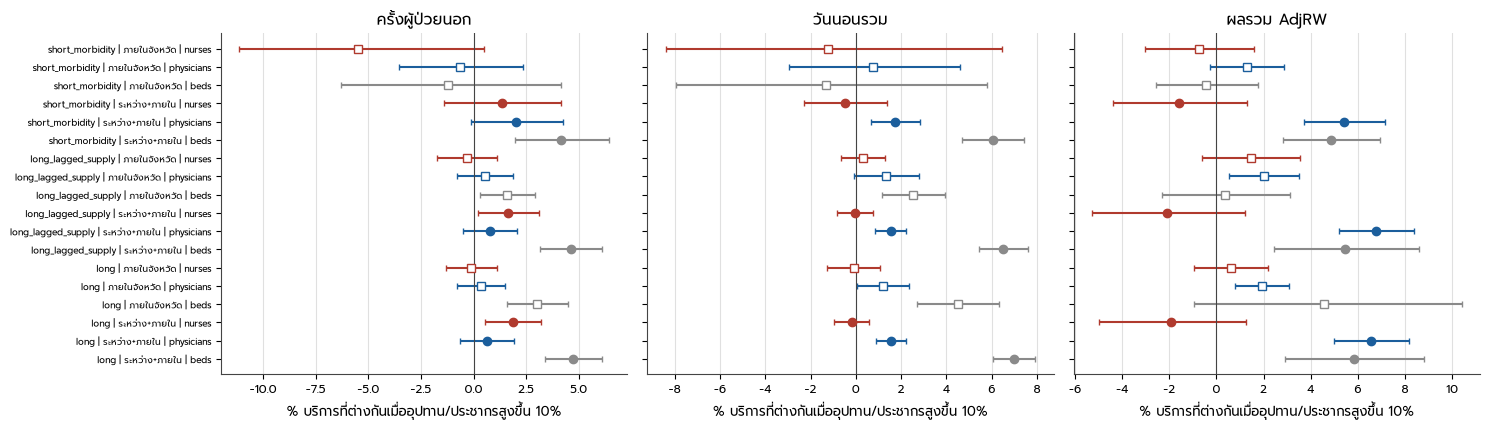

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, o in zip(axes, OUT):
    z = jt[jt.outcome == o].reset_index(drop=True)
    labs = []
    for i, r in z.iterrows():
        col = {"beds": "#8a8a8a", "physicians": R.CADRE_COLOR["แพทย์"], "nurses": R.CADRE_COLOR["พยาบาลวิชาชีพ"]}[r.supply]
        ax.errorbar(r.pct_for_10pct_coef, i, xerr=[[r.pct_for_10pct_coef - r.pct_for_10pct_lo95], [r.pct_for_10pct_hi95 - r.pct_for_10pct_coef]],
                    fmt="o" if r.fe == "pooled_year_fe" else "s", color=col, capsize=2, mfc="white" if r.fe != "pooled_year_fe" else col)
        labs.append(f"{r.panel} | {'ระหว่าง+ภายใน' if r.fe == 'pooled_year_fe' else 'ภายในจังหวัด'} | {r.supply}")
    ax.axvline(0, color="#444", lw=0.8)
    ax.set_yticks(range(len(z))); ax.set_yticklabels(labs, fontsize=6.5); ax.set_title(OUT_TH[o])
    ax.set_xlabel("% บริการที่ต่างกันเมื่ออุปทาน/ประชากรสูงขึ้น 10%"); ax.grid(axis="x", color="#e0e0e0")
fig.tight_layout()
S.figure("F423_SUPPLY_ASSOCIATIONS", fig, jt, "ความสัมพันธ์ระหว่างบริการกับเตียง แพทย์ และพยาบาล (PPML แบบร่วม; ช่วง 95%)", main=True)
plt.show()

## C5. บริการคาดหมายภายใต้เงื่อนไขอ้างอิงเดียวกัน — ใช้ M5 ทั้งแบบจำลอง

$\hat r^{k,*}_{pt}=f^k_{M5}(\mathbf s_{pt},\mathbf d_{pt},GPP^*,b^*,m^*,n^*,t^*)$ ใช้ฟังก์ชันทำนายทั้งหมด (ค่าคงที่และทุกพจน์)
คงโครงสร้างอายุและความชุกที่บันทึกของแต่ละจังหวัด-ปี ตรึงบริบทเศรษฐกิจ เตียง แพทย์ พยาบาล และผลของปีไว้ที่ค่าอ้างอิงชุดเดียว
(ปี 2566, รวม 76 จังหวัด: ความหนาแน่นรวม = ผลรวมทรัพยากร/ผลรวมประชากร แล้วจึง log; GPP = ค่าเฉลี่ยถ่วงประชากรของระดับ GPP ปี 2565 แล้วจึง log)
$V^*=P\hat r^*$ และ $E_{pt}=V^*_{pt}/\bar r_b$ โดย $\bar r_b=\sum_p V^*_{pb}/\sum_p P_{pb}$, b = 2566 (ตรึงไว้ ไม่ปรับรายปี)

ชื่อผลลัพธ์: **การใช้บริการคาดหมายที่ปรับมาตรฐานด้วยแบบจำลอง (model-standardized expected utilization)**
ไม่ใช่ความจำเป็นทั้งหมด ไม่ใช่ unmet need และไม่ใช่ผลเชิงเหตุผลของการเกลี่ยทรัพยากร

In [21]:
REF_Y = MC["reference_year"]
YRS = sorted(Z.year.unique())
ref_rows = panel[panel.year == REF_Y]
assert ref_rows.prov_code.nunique() == 76, "reference year does not cover 76 provinces"
REFS, FITS, STD = {}, {}, []
names_m5 = None
for o in OUT:
    REFS[o] = MD.reference_profile(ref_rows, o, ref_rows)
    X, names_m5 = MD.design(Z, o, FULL, years=YRS)
    b = MD.ols(X, Z[MD.RATE_COL[o]].to_numpy(float))
    FITS[o] = b
    ev = panel[panel.year.isin(YRS) & panel[P.DISEASE].notna().all(axis=1)].copy()
    ev["rate_star"] = MD.standardized_prediction(ev, o, b, names_m5, REFS[o], REF_Y, YRS)
    Xa, _ = MD.design(ev, o, FULL, years=YRS)
    ev["rate_fitted_actual_supply"] = Xa @ b
    ev["outcome"] = o
    ev["V_star"] = ev.population * ev.rate_star
    STD.append(ev[["prov_code", "province", "year", "outcome", "population", "rate_star", "V_star", "rate_fitted_actual_supply", MD.RATE_COL[o]]]
               .rename(columns={MD.RATE_COL[o]: "rate_observed"}))
STD = pd.concat(STD, ignore_index=True)
REFP = pd.DataFrame([dict(outcome=o, reference_year=REF_Y, gpp_year=REF_Y - 1, **v,
                          beds_per1000=np.exp(v["log_beds"]), physicians_per100k=np.exp(v["log_physicians"]),
                          nurses_per100k=np.exp(v["log_nurses"]), gpp_per_capita=np.exp(v["log_gpp_lag1"]),
                          source_sample=f"76 provinces, {REF_Y} (pooled)") for o, v in REFS.items()])
S.table("T423_REFERENCE_PROFILE", REFP, "ค่าอ้างอิงของ M5 standardization (ตรึงทุกจังหวัดทุกปี)", main=True)
COEF = pd.DataFrame({o: FITS[o] for o in OUT}, index=names_m5).reset_index().rename(columns={"index": "term"})
S.table("T423_M5_COEFFICIENTS", COEF, "สัมประสิทธิ์ M5 (OLS บนตัวอย่างร่วม) — ใช้ทำนาย ไม่ใช่ผลเชิงเหตุผล")
display(REFP.round(3))
assert (STD.rate_star > 0).all(), "non-positive standardized prediction - inspect before use"
S.claim("c423_std_nonpositive", int((STD.rate_star <= 0).sum()), "int", "แถว")
# b = reference year normalization, fixed
RB = STD[STD.year == REF_Y].groupby("outcome").apply(lambda g: g.V_star.sum() / g.population.sum(), include_groups=False)
STD["rbar_ref"] = STD.outcome.map(RB)
STD["E_equiv_pop"] = STD.V_star / STD.rbar_ref
chk = STD[STD.year == REF_Y].groupby("outcome")[["E_equiv_pop", "population"]].sum()
assert np.allclose(chk.E_equiv_pop, chk.population)
# supply-invariance verification: change observed supply only, standardized prediction must not move
for o in OUT:
    ev = panel[panel.year.isin(YRS) & panel[P.DISEASE].notna().all(axis=1)].copy()
    pert = ev.copy()
    for c in [MD.BED_COL[o], MD.PHYS, MD.NURS, "log_gpp_lag1"]:
        pert[c] = pert[c] + np.random.default_rng(1).normal(0, 0.5, len(pert))
    a1 = MD.standardized_prediction(ev, o, FITS[o], names_m5, REFS[o], REF_Y, YRS)
    a2 = MD.standardized_prediction(pert, o, FITS[o], names_m5, REFS[o], REF_Y, YRS)
    assert np.allclose(a1, a2), "standardized prediction depends on observed supply"
print("verified: perturbing observed supply and GPP leaves the standardized prediction unchanged")

# samples and index
def idx_table(std, sample, provs, years, base_year):
    z = std[std.prov_code.isin(provs) & std.year.isin(years)]
    g = z.groupby(["outcome", "year"]).agg(V=("V_star", "sum"), P=("population", "sum")).reset_index()
    g["index_V"] = 100 * g.V / g.groupby("outcome").V.transform(lambda s: s[g.loc[s.index, "year"] == base_year].iloc[0])
    g["index_P"] = 100 * g.P / g.groupby("outcome").P.transform(lambda s: s[g.loc[s.index, "year"] == base_year].iloc[0])
    g["sample"] = sample
    return g

prov_all = STD.groupby("prov_code").year.nunique()
BAL = prov_all[prov_all == len(YRS)].index
A76 = STD[STD.year >= 2023].prov_code.unique()
IDX = pd.concat([idx_table(STD, "all76_2023_2025", A76, [2023, 2024, 2025], 2023),
                 idx_table(STD, f"balanced{len(BAL)}_2022_2025", BAL, YRS, 2022)], ignore_index=True)

# province-cluster bootstrap with refitting; reference held fixed (conditional model uncertainty)
B = MC["standardization_bootstrap_draws"]
rng = np.random.default_rng(C.SEED)
provs = np.array(sorted(Z.prov_code.unique()))
pidx = {p: np.flatnonzero(Z.prov_code.to_numpy() == p) for p in provs}
EV = {o: panel[panel.year.isin(YRS) & panel[P.DISEASE].notna().all(axis=1)].copy() for o in OUT}
boot_idx, boot_E, invalid = [], [], {o: 0 for o in OUT}
for bi in range(B):
    draw = rng.choice(provs, len(provs), replace=True)
    ids = np.concatenate([pidx[p] for p in draw])
    zb = Z.iloc[ids]
    for o in OUT:
        X, _ = MD.design(zb, o, FULL, years=YRS)
        bb = MD.ols(X, zb[MD.RATE_COL[o]].to_numpy(float))
        ev = EV[o]
        rs = MD.standardized_prediction(ev, o, bb, names_m5, REFS[o], REF_Y, YRS)
        if not np.all(np.isfinite(rs)) or (rs <= 0).any():
            invalid[o] += 1
            continue
        tmp = ev[["prov_code", "year", "population"]].assign(outcome=o, V_star=ev.population.to_numpy() * rs)
        rb = tmp[tmp.year == REF_Y].V_star.sum() / tmp[tmp.year == REF_Y].population.sum()
        tmp["E_equiv_pop"] = tmp.V_star / rb
        for smp, pv, yrs_, by in [("all76_2023_2025", A76, [2023, 2024, 2025], 2023), (f"balanced{len(BAL)}_2022_2025", BAL, YRS, 2022)]:
            q = tmp[tmp.prov_code.isin(pv) & tmp.year.isin(yrs_)].groupby("year").V_star.sum()
            for y, v in q.items():
                boot_idx.append(dict(draw=bi, outcome=o, sample=smp, year=y, index_V=100 * v / q[by]))
        boot_E.append(tmp[tmp.year == Y1][["prov_code", "outcome", "E_equiv_pop"]].assign(draw=bi))
BI = pd.DataFrame(boot_idx)
ci = BI.groupby(["outcome", "sample", "year"]).index_V.quantile([.025, .975]).unstack().rename(columns={0.025: "lo95", 0.975: "hi95"}).reset_index()
IDX = IDX.merge(ci, on=["outcome", "sample", "year"], how="left")
IDX["bootstrap_valid"] = IDX.outcome.map(lambda o: B - invalid[o])
S.table("T423_M5_STANDARDIZED_INDEX", IDX, "ดัชนีบริการคาดหมายที่ปรับมาตรฐานด้วย M5 เทียบดัชนีประชากร (ตัวอย่างจังหวัดคงที่) พร้อมช่วง 95% จาก bootstrap ที่ประมาณใหม่", main=True)
display(IDX.round(2))
BE = pd.concat(boot_E, ignore_index=True)
S.table("T423_M5_BOOTSTRAP_E_2025", BE, "การกระจายของประชากรเทียบเท่า M5 ปี 2568 จาก bootstrap (ใช้ใน 4.3)")
for r in IDX[IDX.year == IDX.groupby("sample").year.transform("max")].itertuples():
    tag = f"c423_std_{r.sample.split('_')[0]}_{r.outcome}"
    S.claim(tag + "_index", r.index_V, "{:.2f}", "", "T423_M5_STANDARDIZED_INDEX")
    S.claim(tag + "_pct", r.index_V - 100, "{:.2f}", "%")
    S.claim(tag + "_lo", r.lo95 - 100, "{:.2f}", "%")
    S.claim(tag + "_hi", r.hi95 - 100, "{:.2f}", "%")
    S.claim(tag + "_pop_pct", r.index_P - 100, "{:.2f}", "%")
for o in OUT:
    S.claim(f"c423_std_boot_valid_{o}", B - invalid[o], "int", "รอบ")
S.claim("c423_balanced_n", len(BAL), "int", "จังหวัด")

# positive-mean sensitivity of the standardized index (same covariates, quasi-Poisson on rates)
pos = []
for o in OUT:
    X, _ = MD.design(Z, o, FULL, years=YRS)
    bp, ok = MD.fit_positive(X, Z[MD.RATE_COL[o]].to_numpy(float))
    ev = EV[o].copy()
    zz = ev.copy(); zz["year"] = REF_Y
    zz[MD.BED_COL[o]] = REFS[o]["log_beds"]; zz[MD.PHYS] = REFS[o]["log_physicians"]; zz[MD.NURS] = REFS[o]["log_nurses"]; zz["log_gpp_lag1"] = REFS[o]["log_gpp_lag1"]
    Xs, _ = MD.design(zz, o, FULL, years=YRS)
    ev["V_pos"] = ev.population * np.exp(Xs @ bp)
    for smp, pv, yrs_, by in [("all76_2023_2025", A76, [2023, 2024, 2025], 2023), (f"balanced{len(BAL)}_2022_2025", BAL, YRS, 2022)]:
        q = ev[ev.prov_code.isin(pv) & ev.year.isin(yrs_)].groupby("year").V_pos.sum()
        pos.append(dict(outcome=o, sample=smp, converged=ok, end_year=max(yrs_), index_end=100 * q[max(yrs_)] / q[by]))
POS = pd.DataFrame(pos)
S.table("T423_M5_POSITIVE_SENSITIVITY", POS, "ความไวของดัชนีมาตรฐานเมื่อใช้แบบจำลองค่าคาดหมายเป็นบวก (quasi-Poisson)")
display(POS.round(2))

# support: marginal and joint (Mahalanobis) position of the fixed reference profile
sup = []
for o in OUT:
    cols = ["log_gpp_lag1", MD.BED_COL[o], MD.PHYS, MD.NURS]
    X = Z[cols].to_numpy(float)
    ref = np.array([REFS[o]["log_gpp_lag1"], REFS[o]["log_beds"], REFS[o]["log_physicians"], REFS[o]["log_nurses"]])
    mu, cov = X.mean(0), np.cov(X.T)
    ci_ = np.linalg.inv(cov)
    dref = float(np.sqrt((ref - mu) @ ci_ @ (ref - mu)))
    dobs = np.sqrt(np.einsum("ij,jk,ik->i", X - mu, ci_, X - mu))
    for j, c in enumerate(cols):
        sup.append(dict(outcome=o, variable=c, reference=ref[j], sample_min=X[:, j].min(), sample_max=X[:, j].max(),
                        within_range=X[:, j].min() <= ref[j] <= X[:, j].max(),
                        reference_percentile=100 * (X[:, j] < ref[j]).mean()))
    sup.append(dict(outcome=o, variable="JOINT_mahalanobis", reference=dref, sample_min=dobs.min(), sample_max=dobs.max(),
                    within_range=dref <= dobs.max(), reference_percentile=100 * (dobs < dref).mean()))
SUPP = pd.DataFrame(sup)
S.table("T423_M5_SUPPORT", SUPP, "การตรวจ support ของค่าอ้างอิง: รายตัวแปรและร่วม (Mahalanobis)")
display(SUPP.round(3))
for o in OUT:
    S.claim(f"c423_support_joint_pct_{o}", SUPP[(SUPP.outcome == o) & (SUPP.variable == "JOINT_mahalanobis")].reference_percentile.iloc[0], "{:.0f}", "percentile")

# acceptability decision per outcome (criteria fixed here, before reading the index)
acc = []
for o in OUT:
    s_ = SUPP[SUPP.outcome == o]
    crit = dict(positive=(STD[STD.outcome == o].rate_star > 0).all(), all_marginal_in_range=bool(s_[s_.variable != "JOINT_mahalanobis"].within_range.all()),
                joint_support_below_p95=bool(s_[s_.variable == "JOINT_mahalanobis"].reference_percentile.iloc[0] < 95),
                bootstrap_valid_share_ge_95=(B - invalid[o]) / B >= 0.95,
                m5_r2_positive=bool(SC[(SC.model == "M5") & (SC.outcome == o) & (SC.estimator == "ols") & (SC.age_groups == 3)].r2_pred_train_mean.iloc[0] > 0))
    ok = all(crit.values())
    acc.append(dict(outcome=o, **crit, decision="ใช้เป็นตัวหารมาตรฐานได้ (ช่วงสั้น 2565–2568)" if ok else "ไม่ผ่าน — ใช้เป็นข้อมูลประกอบเท่านั้น"))
ACC = pd.DataFrame(acc)
S.table("T423_M5_ACCEPTABILITY", ACC, "เกณฑ์การยอมรับตัวหารมาตรฐาน M5 แยกผลลัพธ์", main=True)
display(ACC)
for r in ACC.itertuples():
    S.text_claim(f"c423_m5_accept_{r.outcome}", r.decision)

DEN_OUT = STD.copy()
DEN_OUT["accepted"] = DEN_OUT.outcome.map(ACC.set_index("outcome").decision.str.startswith("ใช้"))
S.table("T423_M5_DENOMINATORS", DEN_OUT, "ตัวหารมาตรฐาน M5 รายจังหวัด-ปี: บริการคาดหมาย V* และประชากรเทียบเท่า E (ใช้ใน 4.3)", main=True)

,outcome,reference_year,gpp_year,log_beds,log_physicians,log_nurses,log_gpp_lag1,beds_per1000,physicians_per100k,nurses_per100k,gpp_per_capita,source_sample
0,op_moph,2023,2022,0.539,3.577,5.3,12.053,1.715,35.76,200.264,171655.369,"76 provinces, 2023 (pooled)"
1,ip_moph,2023,2022,0.539,3.577,5.3,12.053,1.715,35.76,200.264,171655.369,"76 provinces, 2023 (pooled)"
2,adjrw,2023,2022,0.538,3.577,5.3,12.053,1.713,35.76,200.264,171655.369,"76 provinces, 2023 (pooled)"


verified: perturbing observed supply and GPP leaves the standardized prediction unchanged


,outcome,year,V,P,index_V,index_P,sample,lo95,hi95,bootstrap_valid
0,adjrw,2023,9.738458e+06,59496447,100.00,100.00,all76_2023_2025,100.00,100.00,500
1,adjrw,2024,9.715330e+06,59413776,99.76,99.86,all76_2023_2025,98.30,101.05,500
2,adjrw,2025,9.705912e+06,59316175,99.67,99.70,all76_2023_2025,97.46,101.99,500
3,ip_moph,2023,2.998147e+07,59496447,100.00,100.00,all76_2023_2025,100.00,100.00,500
4,ip_moph,2024,2.967147e+07,59413776,98.97,99.86,all76_2023_2025,98.10,100.07,500
5,ip_moph,2025,2.948905e+07,59316175,98.36,99.70,all76_2023_2025,96.95,100.14,500
6,op_moph,2023,1.272943e+08,59496447,100.00,100.00,all76_2023_2025,100.00,100.00,500
7,op_moph,2024,1.286758e+08,59413776,101.09,99.86,all76_2023_2025,99.41,102.81,500
8,op_moph,2025,1.295098e+08,59316175,101.74,99.70,all76_2023_2025,99.04,104.30,500
9,adjrw,2022,9.393514e+06,57315394,100.00,100.00,balanced74_2022_2025,100.00,100.00,500


,outcome,sample,converged,end_year,index_end
0,op_moph,all76_2023_2025,True,2025,101.52
1,op_moph,balanced74_2022_2025,True,2025,102.84
2,ip_moph,all76_2023_2025,True,2025,98.72
3,ip_moph,balanced74_2022_2025,True,2025,98.23
4,adjrw,all76_2023_2025,True,2025,99.87
5,adjrw,balanced74_2022_2025,True,2025,100.08


,outcome,variable,reference,sample_min,sample_max,within_range,reference_percentile
0,op_moph,log_gpp_lag1,12.053,11.031,13.824,True,74.172
1,op_moph,log_beds_moph_per1000,0.539,-0.417,1.118,True,33.775
2,op_moph,log_moph_physicians_per100k,3.577,2.852,4.195,True,46.689
3,op_moph,log_moph_professional_nurses_per100k,5.300,4.562,5.846,True,42.715
4,op_moph,JOINT_mahalanobis,0.411,0.436,4.872,True,0.000
5,ip_moph,log_gpp_lag1,12.053,11.031,13.824,True,74.172
6,ip_moph,log_beds_moph_per1000,0.539,-0.417,1.118,True,33.775
7,ip_moph,log_moph_physicians_per100k,3.577,2.852,4.195,True,46.689
8,ip_moph,log_moph_professional_nurses_per100k,5.300,4.562,5.846,True,42.715
9,ip_moph,JOINT_mahalanobis,0.411,0.436,4.872,True,0.000


,outcome,positive,all_marginal_in_range,joint_support_below_p95,bootstrap_valid_share_ge_95,m5_r2_positive,decision
0,op_moph,True,True,True,True,True,ใช้เป็นตัวหารมาตรฐานได้ (ช่วงสั้น 2565–2568)
1,ip_moph,True,True,True,True,True,ใช้เป็นตัวหารมาตรฐานได้ (ช่วงสั้น 2565–2568)
2,adjrw,True,True,True,True,True,ใช้เป็นตัวหารมาตรฐานได้ (ช่วงสั้น 2565–2568)


,prov_code,province,year,outcome,population,rate_star,V_star,rate_fitted_actual_supply,rate_observed,rbar_ref,E_equiv_pop,accepted
0,11,สมุทรปราการ,2022,op_moph,1335251,2.066612,2.759446e+06,1.835066,1.356597,2.139527,1.289746e+06,True
1,11,สมุทรปราการ,2023,op_moph,1349023,2.073503,2.797203e+06,1.074879,1.109602,2.139527,1.307393e+06,True
2,11,สมุทรปราการ,2024,op_moph,1358940,2.104593,2.860015e+06,1.156466,1.131653,2.139527,1.336751e+06,True
3,11,สมุทรปราการ,2025,op_moph,1362481,2.127295,2.898399e+06,1.386412,1.207644,2.139527,1.354691e+06,True
4,12,นนทบุรี,2022,op_moph,1270322,2.278948,2.894998e+06,2.411744,1.290330,2.139527,1.353102e+06,True
...,...,...,...,...,...,...,...,...,...,...,...,...
901,95,ยะลา,2025,adjrw,552322,0.131431,7.259217e+04,0.160049,0.211315,0.163681,4.434969e+05,True
902,96,นราธิวาส,2022,adjrw,809443,0.147019,1.190034e+05,0.123592,0.106379,0.163681,7.270435e+05,True
903,96,นราธิวาส,2023,adjrw,814314,0.146858,1.195886e+05,0.129377,0.116176,0.163681,7.306185e+05,True
904,96,นราธิวาส,2024,adjrw,818904,0.146820,1.202317e+05,0.140555,0.129032,0.163681,7.345474e+05,True


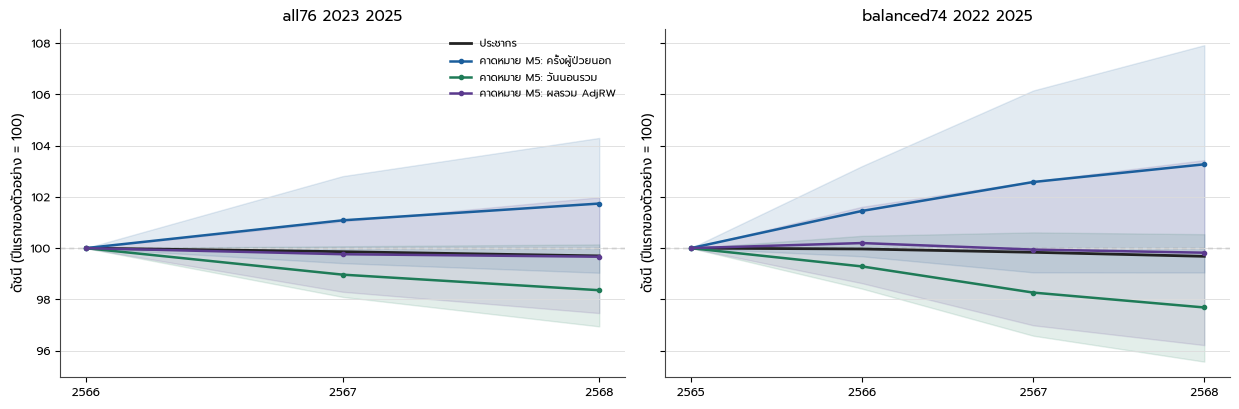

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, smp in zip(axes, IDX["sample"].unique()):
    z = IDX[IDX["sample"] == smp]
    p_ = z[z.outcome == OUT[0]]
    ax.plot(p_.year, p_.index_P, color="#222", lw=2, label="ประชากร")
    for o, col in zip(OUT, ["#1b5e9c", "#1e7b57", "#5b3a8e"]):
        q = z[z.outcome == o]
        ax.plot(q.year, q.index_V, color=col, lw=1.8, marker="o", ms=3, label=f"คาดหมาย M5: {OUT_TH[o]}")
        ax.fill_between(q.year, q.lo95, q.hi95, color=col, alpha=0.12)
    ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, sorted(z.year.unique()), 1); ax.grid(**R.GRID_KW)
    ax.set_title(smp.replace("_", " ")); ax.set_ylabel("ดัชนี (ปีแรกของตัวอย่าง = 100)")
axes[0].legend(frameon=False, fontsize=7.5)
fig.tight_layout()
S.figure("F423_M5_STANDARDIZED_TREND", fig, IDX, "บริการคาดหมายภายใต้เงื่อนไขอ้างอิง M5 เทียบประชากร (จังหวัดชุดคงที่; แถบ = ช่วง 95%)", main=True)
plt.show()

## C6. น้ำหนักอายุอย่างเดียว: สองคำถามที่ต้องแยกกัน

**คำถาม 1** โครงสร้างอายุช่วยทำนายหรือไม่ → ใช้ผล M0→M1 นอกตัวอย่าง (C2) และ C3

**คำถาม 2** ประมาณอัตราการใช้บริการสัมพัทธ์รายกลุ่มอายุที่เสถียรพอใช้เป็นตัวหารได้หรือไม่ → สมการ
$r_{pt}=q_t\sum_a s_{pta}\rho_a$, $\rho_a\ge 0$, $q_{t_0}=1$ (ผลของปีเป็นตัวคูณ) และน้ำหนัก $w_a=\rho_a/\bar\rho_{2556}$
ข้อมูลโครงการ **ไม่มี** การใช้บริการแยกตามอายุผู้ป่วย และไม่มีตารางอัตราอ้างอิงภายนอกที่ตรวจสอบได้

เกณฑ์ยอมรับ (ประกาศใน config ก่อนประมาณ): สัดส่วนน้ำหนักที่ติดขอบศูนย์ ≤ 0.25; ช่วง bootstrap ของน้ำหนัก 60+ (97.5/2.5) ≤ 3;
น้ำหนัก 60+ เมื่อเปลี่ยนการจัดกลุ่มอายุ (3 vs 6 กลุ่ม) ต่างกันไม่เกิน 3 เท่า; ลำดับน้ำหนักเหมือนกันเมื่อเปลี่ยนขอบเขตบริการ

In [23]:
AW = C.CFG["age_weights"]
age_rows, age_boot, age_diag = [], [], []
LONG = {"op_moph": panel[np.isfinite(panel.op_moph_pc)], "ip_moph": panel[np.isfinite(panel.ip_moph_pc)],
        "adjrw": panel[np.isfinite(panel.adjrw_pc)]}
# universe sensitivity: all-reporting outcomes
panel_all = panel.assign(op_all_pc=panel.all_op_visits / panel.population, ip_all_pc=panel.all_ip_days / panel.population)
MD.RATE_COL.update({"op_all": "op_all_pc", "ip_all": "ip_all_pc"})
VARIANTS = [(o, "long", LONG[o], k) for o in OUT for k in (3, 6)] + \
           [(o, "pre_covid_2013_2019", LONG[o][LONG[o].year <= 2019], 3) for o in ["op_moph", "ip_moph"]] + \
           [(o, "morbidity_years", Z, 3) for o in OUT] + \
           [(o, "long_all_reporting", panel_all[np.isfinite(panel_all[MD.RATE_COL[o]])], 3) for o in ["op_all", "ip_all"]]
base_counts = {k: panel[panel.year == panel.year.min()][[f"n{k}_{g}" for _, _, g in P.AGE_BANDS[k]]].sum().to_numpy(float) for k in (3, 6)}
for o, var, z, k in VARIANTS:
    z = z.reset_index(drop=True)
    f = MD.age_mixture(z, o, k)
    alt = MD.age_mixture(z, o, k, start=np.linspace(0.3, 3, k) * z[MD.RATE_COL[o]].mean())
    gap = abs(alt["cost"] - f["cost"])
    if alt["cost"] < f["cost"]:
        f = alt
    w = MD.age_weights(f["rates"], base_counts[k])
    age_diag.append(dict(outcome=o, variant=var, groups=k, n=len(z), converged=f["success"], multistart_cost_gap=gap, share_at_bound=f["at_bound"]))
    Ws = []
    nb = AW["bootstrap_draws"] if var in ("long",) else 0
    rng = np.random.default_rng(C.SEED + len(age_rows))
    pv = np.array(sorted(z.prov_code.unique()))
    pix = {p: np.flatnonzero(z.prov_code.to_numpy() == p) for p in pv}
    for bi in range(nb):
        ids = np.concatenate([pix[p] for p in rng.choice(pv, len(pv))])
        fb = MD.age_mixture(z.iloc[ids].reset_index(drop=True), o, k, start=f["rates"])
        if fb["success"]:
            wb = MD.age_weights(fb["rates"], base_counts[k])
            Ws.append(wb)
            for j, (_, _, g) in enumerate(P.AGE_BANDS[k]):
                age_boot.append(dict(outcome=o, variant=var, groups=k, draw=bi, age=g, weight=wb[j]))
    Ws = np.array(Ws)
    for j, (_, _, g) in enumerate(P.AGE_BANDS[k]):
        age_rows.append(dict(outcome=o, variant=var, groups=k, age=g, rate=f["rates"][j], weight=w[j],
                             lo95=np.percentile(Ws[:, j], 2.5) if len(Ws) else np.nan,
                             hi95=np.percentile(Ws[:, j], 97.5) if len(Ws) else np.nan,
                             boot_share_zero=(Ws[:, j] < 1e-6).mean() if len(Ws) else np.nan, n_boot=len(Ws)))
AGEW = pd.DataFrame(age_rows)
S.table("T423_AGE_WEIGHTS", AGEW, "อัตราและน้ำหนักการใช้บริการสัมพัทธ์รายกลุ่มอายุที่ประมาณจากข้อมูลรวมระดับจังหวัด", main=True)
S.table("T423_AGE_WEIGHT_DIAGNOSTICS", pd.DataFrame(age_diag), "การลู่เข้าและ multistart ของการประมาณน้ำหนักอายุ")
S.table("T423_AGE_WEIGHT_BOOTSTRAP", pd.DataFrame(age_boot), "bootstrap ของน้ำหนักอายุ")
display(AGEW.round(3))

# implied 60+ weight for the six-group fit (base-year population weighted)
def w60(o, var, k):
    z = AGEW[(AGEW.outcome == o) & (AGEW.variant == var) & (AGEW.groups == k)].set_index("age").weight
    if k == 3:
        return z["60+"]
    n = dict(zip([g for _, _, g in P.AGE_BANDS[6]], base_counts[6]))
    return (z["60-74"] * n["60-74"] + z["75+"] * n["75+"]) / (n["60-74"] + n["75+"])

VERD = []
for o in OUT:
    main_ = AGEW[(AGEW.outcome == o) & (AGEW.variant == "long") & (AGEW.groups == 3)].set_index("age")
    bound = float((main_.weight < 1e-6).mean())
    ratio_boot = main_.hi95["60+"] / main_.lo95["60+"] if main_.lo95["60+"] > 0 else np.inf
    w3, w6 = w60(o, "long", 3), w60(o, "long", 6)
    ratio_group = max(w3, w6) / min(w3, w6) if min(w3, w6) > 0 else np.inf
    same_order = True
    if o in ("op_moph", "ip_moph"):
        alt_ = AGEW[(AGEW.outcome == o.replace("moph", "all")) & (AGEW.groups == 3)].set_index("age").weight
        same_order = list(np.argsort(main_.weight.values)) == list(np.argsort(alt_.values))
    crit = dict(share_at_bound_ok=bound <= AW["max_share_at_bound"], bootstrap_ratio_60p=ratio_boot,
                bootstrap_ok=ratio_boot <= AW["max_bootstrap_ratio"], grouping_ratio_60p=ratio_group,
                grouping_ok=ratio_group <= AW["max_ratio_across_specs"], universe_order_ok=same_order)
    ok = crit["share_at_bound_ok"] and crit["bootstrap_ok"] and crit["grouping_ok"] and crit["universe_order_ok"]
    g01 = GAINS[(GAINS.outcome == o) & (GAINS.baseline == "M0") & (GAINS.model == "M1") & (GAINS.estimator == "ols") & (GAINS.age_groups == 3)].iloc[0]
    q1 = ("ช่วยทำนาย" if g01.lo95 > 0 else ("ทำนายแย่ลง" if g01.hi95 < 0 else "ยังสรุปทิศทางไม่ได้"))
    VERD.append(dict(outcome=o, question="1: อายุช่วยทำนายนอกตัวอย่างหรือไม่ (M0→M1)", sample=f"{len(Z)} จังหวัด-ปี 2565–2568",
                     evidence=f"SSE ลดลง {g01.sse_reduction_pct:.1f}% (95%: {g01.lo95:.1f} ถึง {g01.hi95:.1f})", decision=q1,
                     permitted_use="เป็นหลักฐานเชิงทำนาย ไม่ใช่อัตรารายอายุ", reason="ผลต่างของสัดส่วนอายุกับกลุ่มอ้างอิง ไม่ใช่อัตราการใช้บริการ"))
    VERD.append(dict(outcome=o, question="2: น้ำหนักอายุเสถียรพอเป็นตัวหารหรือไม่", sample=f"แผงยาว {LONG[o].year.min()}–{LONG[o].year.max()}",
                     evidence=f"ติดขอบศูนย์ {bound:.2f}; ช่วง bootstrap น้ำหนัก 60+ = {ratio_boot:.1f} เท่า; 3 vs 6 กลุ่ม = {ratio_group:.1f} เท่า; ลำดับเท่ากันข้ามขอบเขต = {same_order}",
                     decision="ใช้ได้" if ok else "ใช้ไม่ได้เป็นตัวหาร",
                     permitted_use="ตัวหารอายุที่ประมาณได้" if ok else "ใช้เฉพาะฉากทัศน์น้ำหนักอายุที่ประกาศเป็นสมมติฐาน",
                     reason="ผ่านเกณฑ์ทุกข้อ" if ok else "ไม่ผ่านเกณฑ์: " + ", ".join(k for k, v in crit.items() if k.endswith("ok") and not v)))
    for k_, v in crit.items():
        if not isinstance(v, (bool, np.bool_)):
            S.claim(f"c423_age_{o}_{k_}", v, "{:.1f}", "เท่า")
    S.claim(f"c423_age_{o}_w60", w3, "{:.2f}", "")
    S.claim(f"c423_age_{o}_w60_lo", main_.lo95["60+"], "{:.2f}", "")
    S.claim(f"c423_age_{o}_w60_hi", main_.hi95["60+"], "{:.2f}", "")
    S.claim(f"c423_age_{o}_w014", main_.weight["0-14"], "{:.2f}", "")
AGEV = pd.DataFrame(VERD)
S.table("T423_AGE_WEIGHT_VERDICT", AGEV, "ข้อสรุปเรื่องน้ำหนักอายุ แยกคำถามเชิงทำนาย และคำถามการประมาณอัตรารายอายุ", main=True)
display(AGEV)
for r in AGEV[AGEV.question.str.startswith("2")].itertuples():
    S.text_claim(f"c423_age_verdict_{r.outcome}", r.decision)
for r in AGEV[AGEV.question.str.startswith("1")].itertuples():
    S.text_claim(f"c423_age_q1_{r.outcome}", r.decision)
ACCEPTED_AGE = [r.outcome for r in AGEV.itertuples() if r.question.startswith("2") and r.decision == "ใช้ได้"]

# age-weighted population: estimated weights where accepted, otherwise declared scenarios
SCEN_W = {"flat": {"0-14": 1.0, "15-59": 1.0, "60+": 1.0}, "moderate": {"0-14": 0.8, "15-59": 1.0, "60+": 2.0},
          "steep": {"0-14": 0.8, "15-59": 1.0, "60+": 3.0}}
ap = P.age_shares()
aw_rows = []
for name, wd in SCEN_W.items():
    w = np.array([wd[g] for _, _, g in P.AGE_BANDS[3]])
    raw = ap[[f"n3_{g}" for _, _, g in P.AGE_BANDS[3]]].to_numpy(float) @ w
    nat0 = ap[ap.year == Y0]
    norm = nat0.population.sum() / (nat0[[f"n3_{g}" for _, _, g in P.AGE_BANDS[3]]].to_numpy(float) @ w).sum()
    aw_rows.append(ap[["year", "prov_code", "population"]].assign(scheme=f"scenario_{name}", status="assumed scenario",
                                                                  age_weighted_pop=raw * norm))
for o in ACCEPTED_AGE:
    w = AGEW[(AGEW.outcome == o) & (AGEW.variant == "long") & (AGEW.groups == 3)].weight.to_numpy()
    raw = ap[[f"n3_{g}" for _, _, g in P.AGE_BANDS[3]]].to_numpy(float) @ w
    nat0 = ap[ap.year == Y0]
    norm = nat0.population.sum() / (nat0[[f"n3_{g}" for _, _, g in P.AGE_BANDS[3]]].to_numpy(float) @ w).sum()
    aw_rows.append(ap[["year", "prov_code", "population"]].assign(scheme=f"estimated_{o}", status="estimated, accepted", age_weighted_pop=raw * norm))
AWP = pd.concat(aw_rows, ignore_index=True)
S.table("T423_AGE_WEIGHTED_POPULATION", AWP, "ประชากรถ่วงน้ำหนักอายุ (ตรึงการปรับมาตรฐานที่ปี 2556 ทั้งประเทศ 77 จังหวัด)")
S.table("T423_AGE_SCENARIO_WEIGHTS", pd.DataFrame(SCEN_W).T.reset_index().rename(columns={"index": "scheme"}), "น้ำหนักอายุที่เป็นสมมติฐาน (ไม่ใช่ค่าประมาณ)")
awn = AWP.groupby(["scheme", "year"]).age_weighted_pop.sum().unstack(0)
for sch in awn:
    S.claim(f"c423_awpop_{sch}_pct", M.pct_change(awn[sch][Y0], awn[sch][Y1]), "{:.2f}", "%")
S.claim("c423_share60_2013", ap[ap.year == Y0]["n3_60+"].sum() / ap[ap.year == Y0].population.sum() * 100, "{:.2f}", "%")
S.claim("c423_share60_2025", ap[ap.year == Y1]["n3_60+"].sum() / ap[ap.year == Y1].population.sum() * 100, "{:.2f}", "%")

,outcome,variant,groups,age,rate,weight,lo95,hi95,boot_share_zero,n_boot
0,op_moph,long,3,0-14,3.562,1.756,1.010,2.478,0.000,300
1,op_moph,long,3,15-59,0.000,0.000,0.000,0.100,0.953,300
2,op_moph,long,3,60+,9.994,4.926,3.932,5.927,0.000,300
3,op_moph,long,6,0-14,3.419,1.694,0.000,2.251,0.043,300
4,op_moph,long,6,15-29,0.000,0.000,0.000,1.594,0.780,300
5,op_moph,long,6,30-44,0.000,0.000,0.000,0.000,0.997,300
6,op_moph,long,6,45-59,0.000,0.000,0.000,0.951,0.723,300
7,op_moph,long,6,60-74,6.535,3.237,0.528,4.704,0.013,300
8,op_moph,long,6,75+,19.638,9.728,5.046,16.042,0.000,300
9,ip_moph,long,3,0-14,1.402,3.036,2.245,3.575,0.000,300


,outcome,question,sample,evidence,decision,permitted_use,reason
0,op_moph,1: อายุช่วยทำนายนอกตัวอย่างหรือไม่ (M0→M1),302 จังหวัด-ปี 2565–2568,SSE ลดลง 14.5% (95%: -2.0 ถึง 27.1),ยังสรุปทิศทางไม่ได้,เป็นหลักฐานเชิงทำนาย ไม่ใช่อัตรารายอายุ,ผลต่างของสัดส่วนอายุกับกลุ่มอ้างอิง ไม่ใช่อัตร...
1,op_moph,2: น้ำหนักอายุเสถียรพอเป็นตัวหารหรือไม่,แผงยาว 2013–2025,ติดขอบศูนย์ 0.33; ช่วง bootstrap น้ำหนัก 60+ =...,ใช้ไม่ได้เป็นตัวหาร,ใช้เฉพาะฉากทัศน์น้ำหนักอายุที่ประกาศเป็นสมมติฐาน,"ไม่ผ่านเกณฑ์: share_at_bound_ok, universe_orde..."
2,ip_moph,1: อายุช่วยทำนายนอกตัวอย่างหรือไม่ (M0→M1),302 จังหวัด-ปี 2565–2568,SSE ลดลง 4.9% (95%: -11.2 ถึง 16.5),ยังสรุปทิศทางไม่ได้,เป็นหลักฐานเชิงทำนาย ไม่ใช่อัตรารายอายุ,ผลต่างของสัดส่วนอายุกับกลุ่มอ้างอิง ไม่ใช่อัตร...
3,ip_moph,2: น้ำหนักอายุเสถียรพอเป็นตัวหารหรือไม่,แผงยาว 2013–2025,ติดขอบศูนย์ 0.33; ช่วง bootstrap น้ำหนัก 60+ =...,ใช้ไม่ได้เป็นตัวหาร,ใช้เฉพาะฉากทัศน์น้ำหนักอายุที่ประกาศเป็นสมมติฐาน,ไม่ผ่านเกณฑ์: share_at_bound_ok
4,adjrw,1: อายุช่วยทำนายนอกตัวอย่างหรือไม่ (M0→M1),302 จังหวัด-ปี 2565–2568,SSE ลดลง -6.5% (95%: -21.0 ถึง 6.1),ยังสรุปทิศทางไม่ได้,เป็นหลักฐานเชิงทำนาย ไม่ใช่อัตรารายอายุ,ผลต่างของสัดส่วนอายุกับกลุ่มอ้างอิง ไม่ใช่อัตร...
5,adjrw,2: น้ำหนักอายุเสถียรพอเป็นตัวหารหรือไม่,แผงยาว 2018–2025,ติดขอบศูนย์ 0.00; ช่วง bootstrap น้ำหนัก 60+ =...,ใช้ไม่ได้เป็นตัวหาร,ใช้เฉพาะฉากทัศน์น้ำหนักอายุที่ประกาศเป็นสมมติฐาน,ไม่ผ่านเกณฑ์: bootstrap_ok


21.8008504412796

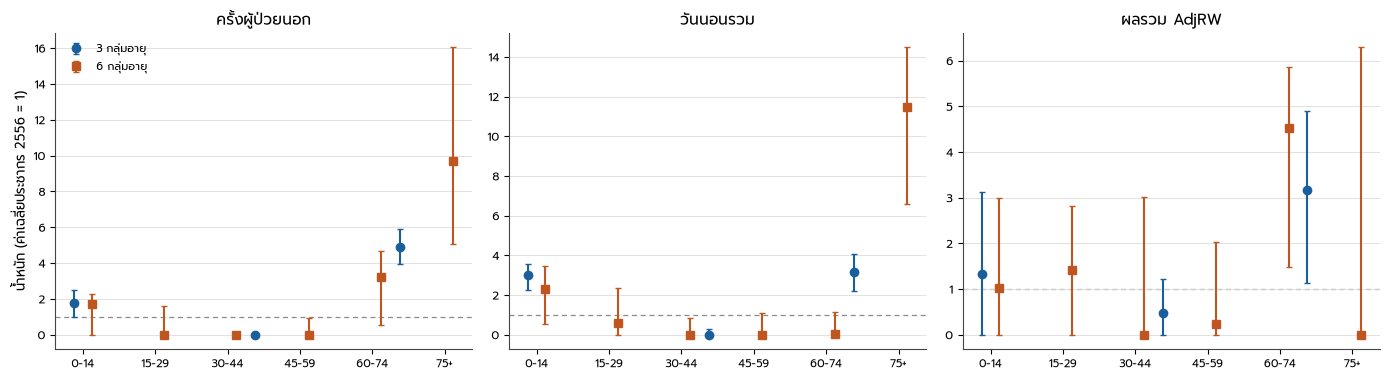

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=False)
for ax, o in zip(axes, OUT):
    for k, off, mk in [(3, -0.12, "o"), (6, 0.12, "s")]:
        z = AGEW[(AGEW.outcome == o) & (AGEW.variant == "long") & (AGEW.groups == k)].reset_index(drop=True)
        xs = np.arange(len(z)) if k == 6 else np.array([0, 2.5, 4.5])
        ax.errorbar(xs + off, z.weight, yerr=[np.clip(z.weight - z.lo95.fillna(z.weight), 0, None), np.clip(z.hi95.fillna(z.weight) - z.weight, 0, None)],
                    fmt=mk, capsize=2, label=f"{k} กลุ่มอายุ", color="#1b5e9c" if k == 3 else "#c0561f")
    ax.set_xticks(range(6)); ax.set_xticklabels([g for _, _, g in P.AGE_BANDS[6]], fontsize=8)
    ax.axhline(1, **R.REFLINE_KW); ax.set_title(OUT_TH[o]); ax.grid(**R.GRID_KW)
axes[0].set_ylabel("น้ำหนัก (ค่าเฉลี่ยประชากร 2556 = 1)"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F423_AGE_WEIGHTS", fig, AGEW, "น้ำหนักอายุที่ประมาณจากข้อมูลรวมระดับจังหวัด พร้อมช่วง 95% (bootstrap จังหวัด)")
plt.show()

## C7. จากบริการคาดหมายสู่ความจำเป็นเชิงบรรทัดฐาน — ความพร้อมของข้อมูล
$\text{ผู้มีสิทธิ์/เหตุการณ์}\times\text{กิจกรรมที่เหมาะสมต่อคน}\times\text{เป้าความครอบคลุม}\times\text{เวลาต่อกิจกรรมแยกวิชาชีพ}\rightarrow\text{ชั่วโมง/FTE ที่ต้องการ}$

In [25]:
READY = pd.DataFrame([
    dict(input="จำนวนผู้ป่วยที่วินิจฉัยแล้วรายโรค (DM, HT, CKD 3–5, COPD, stroke, CHD)", status="มี (HDC 2565–2568)", type="วัดได้", gap="เป็นความชุกที่วินิจฉัยแล้ว ไม่ใช่ความชุกจริง; ไม่แยกโรคร่วม"),
    dict(input="ความชุกจริงจากการสำรวจ (เช่น NHES) รายจังหวัด", status="ไม่มีในโครงการ", type="วัดได้", gap="ต้องการเพื่อประมาณผู้ที่ยังไม่ได้วินิจฉัย"),
    dict(input="ชุดบริการที่เหมาะสมต่อผู้ป่วยต่อปี (care package) แยกโรค", status="ไม่มี", type="มาตรฐานทางคลินิก", gap="ต้องใช้แนวเวชปฏิบัติและฉันทามติ"),
    dict(input="เป้าความครอบคลุม", status="ไม่มี", type="ทางเลือกเชิงนโยบาย", gap="ต้องกำหนดโดยผู้ตัดสินใจ"),
    dict(input="เวลาต่อกิจกรรมแยกวิชาชีพและการแบ่งงาน (task sharing)", status="ไม่มี (มีเพียงค่าสมมติฐานประกอบภาพใน 4.2.2)", type="พารามิเตอร์จากการศึกษา", gap="ต้องการ time-motion หรือมาตรฐานวิชาชีพที่ตรวจสอบได้"),
    dict(input="ชั่วโมงทำงานต่อ FTE และสัดส่วนเวลาบริการตรง", status="ไม่มี", type="วัดได้/นโยบาย", gap="headcount ไม่ใช่ FTE"),
    dict(input="ภาวะพึ่งพิง/ADL ผู้สูงอายุ", status="ไม่มี", type="วัดได้", gap="ต้องการสำหรับงานดูแลระยะยาว"),
    dict(input="สุขภาพช่องปาก (ความจำเป็นทันตกรรม)", status="ไม่มี", type="วัดได้", gap="มีเพียงจำนวนครั้งบริการ"),
    dict(input="การส่งต่อและการเข้าถึง (ระยะทาง เวลา ผู้ป่วยข้ามจังหวัด)", status="ไม่มี", type="วัดได้", gap="แยกความรับผิดชอบพื้นที่กับบริการส่งต่อไม่ได้")])
S.table("T423_NEED_READINESS", READY, "ความพร้อมของข้อมูลสำหรับการคำนวณความจำเป็นเชิงบรรทัดฐาน (ไม่มีการสร้างตัวเลข FTE ที่ต้องการ)", main=True)
display(READY)

,input,status,type,gap
0,"จำนวนผู้ป่วยที่วินิจฉัยแล้วรายโรค (DM, HT, CKD...",มี (HDC 2565–2568),วัดได้,เป็นความชุกที่วินิจฉัยแล้ว ไม่ใช่ความชุกจริง; ...
1,ความชุกจริงจากการสำรวจ (เช่น NHES) รายจังหวัด,ไม่มีในโครงการ,วัดได้,ต้องการเพื่อประมาณผู้ที่ยังไม่ได้วินิจฉัย
2,ชุดบริการที่เหมาะสมต่อผู้ป่วยต่อปี (care packa...,ไม่มี,มาตรฐานทางคลินิก,ต้องใช้แนวเวชปฏิบัติและฉันทามติ
3,เป้าความครอบคลุม,ไม่มี,ทางเลือกเชิงนโยบาย,ต้องกำหนดโดยผู้ตัดสินใจ
4,เวลาต่อกิจกรรมแยกวิชาชีพและการแบ่งงาน (task sh...,ไม่มี (มีเพียงค่าสมมติฐานประกอบภาพใน 4.2.2),พารามิเตอร์จากการศึกษา,ต้องการ time-motion หรือมาตรฐานวิชาชีพที่ตรวจส...
5,ชั่วโมงทำงานต่อ FTE และสัดส่วนเวลาบริการตรง,ไม่มี,วัดได้/นโยบาย,headcount ไม่ใช่ FTE
6,ภาวะพึ่งพิง/ADL ผู้สูงอายุ,ไม่มี,วัดได้,ต้องการสำหรับงานดูแลระยะยาว
7,สุขภาพช่องปาก (ความจำเป็นทันตกรรม),ไม่มี,วัดได้,มีเพียงจำนวนครั้งบริการ
8,การส่งต่อและการเข้าถึง (ระยะทาง เวลา ผู้ป่วยข้...,ไม่มี,วัดได้,แยกความรับผิดชอบพื้นที่กับบริการส่งต่อไม่ได้


---
# ส่วน D — 4.2.4 ตัวหารที่ต่างกันให้ภาพความก้าวหน้าต่างกันอย่างไร
ตัวเศษเดียวกัน (แพทย์และพยาบาลวิชาชีพ; 76 จังหวัด) เทียบกับตัวหารหลายชนิด ในช่วงยาวที่แต่ละตัวหารมี และช่วงร่วม 2566–2568
ไม่ต่อชุดตัวหารแบบจำลองช่วงสั้นเข้ากับชุดสังเกตช่วงยาว

In [26]:
p76 = panel
wf76 = {u: P.workforce_province(u)[lambda d: d.prov_code != BK] for u in ["moph", "all_sectors"]}
den_series = {}
den_series["civil_population"] = p76.groupby("year").population.sum()
den_series["entitlement_population"] = p76.groupby("year").pop_nhso.sum()
for sch in awn:
    den_series[f"age_weighted_{sch}"] = AWP[(AWP.scheme == sch) & (AWP.prov_code != BK)].groupby("year").age_weighted_pop.sum()
den_series["op_visits_moph"] = p76.groupby("year").moph_op_visits.sum()
den_series["ip_days_moph"] = p76.groupby("year").moph_ip_days.sum()
den_series["adjrw_casemix"] = p76.groupby("year").sum_adjrw.sum(min_count=1).dropna()
for o in OUT:
    z = STD[(STD.outcome == o) & STD.prov_code.isin(A76) & (STD.year >= 2023)]
    den_series[f"m5_expected_{o}"] = z.groupby("year").V_star.sum()
MEANING = {"civil_population": ("ประชากรที่อาศัย/ลงทะเบียนตามนิยามทะเบียนราษฎร", "นับทุกคนเท่ากัน ไม่สะท้อนความต่างของความต้องการดูแล"),
           "entitlement_population": ("ผู้ลงทะเบียนสิทธิการรักษา", "ทะเบียนสิทธิกับความรับผิดชอบบริการอาจไม่ตรงกับที่อยู่จริง"),
           "op_visits_moph": ("งานผู้ป่วยนอกที่เข้าสู่ระบบรายงาน", "ขึ้นกับการเข้าถึง การส่งต่อ ขีดความสามารถ และการรายงาน"),
           "ip_days_moph": ("งานผู้ป่วยในที่เข้าสู่ระบบรายงาน", "เช่นเดียวกัน และได้รับผลโควิด-19"),
           "adjrw_casemix": ("ผู้ป่วยในที่ถ่วงความซับซ้อน", "รวมผลการเปลี่ยนการให้รหัส/การจัดกลุ่ม"),
           "m5_expected_op_moph": ("บริการ OP คาดหมายภายใต้ค่าอ้างอิงร่วม", "ยังผูกกับความสัมพันธ์ที่สังเกตและโรคที่บันทึก"),
           "m5_expected_ip_moph": ("วันนอนคาดหมายภายใต้ค่าอ้างอิงร่วม", "เช่นเดียวกัน"),
           "m5_expected_adjrw": ("AdjRW คาดหมายภายใต้ค่าอ้างอิงร่วม", "เช่นเดียวกัน")}
for sch in awn:
    MEANING[f"age_weighted_{sch}"] = ("การเปลี่ยนโครงสร้างอายุภายใต้ตารางน้ำหนักที่ระบุ", "น้ำหนักเป็นสมมติฐาน" if sch.startswith("scenario") else "ประมาณจากการใช้บริการที่ถูกจำกัดด้วยการเข้าถึง")
mat = []
for u, wdf in wf76.items():
    for c in ["แพทย์", "พยาบาลวิชาชีพ"]:
        w = wdf[wdf.cadre == c].groupby("year").headcount.sum()
        for dn, ds in den_series.items():
            yrs_ = sorted(set(ds.index) & set(w.index))
            ratio = w[yrs_] / ds[yrs_]
            for win, (a, b) in {"long": (yrs_[0], yrs_[-1]), "common_2023_2025": (2023, 2025)}.items():
                if a not in ratio.index or b not in ratio.index or a == b:
                    continue
                mat.append(dict(workforce=u, cadre=c, denominator=dn, window=win, start=a, end=b,
                                ratio_pct_change=M.pct_change(ratio[a], ratio[b]),
                                ratio_cagr_pct=100 * M.cagr(ratio[a], ratio[b], b - a),
                                workforce_pct_change=M.pct_change(w[a], w[b]), denominator_pct_change=M.pct_change(ds[a], ds[b]),
                                responsibility=MEANING.get(dn, ("", ""))[0], interpretation_issue=MEANING.get(dn, ("", ""))[1]))
MAT = pd.DataFrame(mat)
S.table("T424_DENOMINATOR_MATRIX", MAT, "กำลังคนชุดเดียวกัน เทียบตัวหารต่างชนิด: การเปลี่ยนแปลงของอัตราส่วนช่วงยาวและช่วงร่วม (76 จังหวัด)", main=True)
display(MAT[(MAT.workforce == "moph")].pivot_table(index="denominator", columns=["cadre", "window"], values="ratio_pct_change").round(2))
for r in MAT.itertuples():
    S.claim(f"c424_{r.workforce}_{EN[r.cadre]}_{r.denominator}_{r.window}", r.ratio_pct_change, "{:.2f}", "%", "T424_DENOMINATOR_MATRIX")
    S.claim(f"c424_{r.workforce}_{EN[r.cadre]}_{r.denominator}_{r.window}_cagr", r.ratio_cagr_pct, "{:.2f}", "% ต่อปี")
MEAN_T = pd.DataFrame([dict(denominator=k, responsibility=v[0], interpretation_issue=v[1]) for k, v in MEANING.items()] +
                      [dict(denominator="normative_care_requirement", responsibility="บริการที่ประชากรควรได้รับตามชุดการดูแลที่กำหนด",
                            interpretation_issue="ประมาณไม่ได้ด้วยข้อมูลโครงการ (ดู T423_NEED_READINESS)")])
S.table("T424_DENOMINATOR_MEANING", MEAN_T, "ตัวหารแต่ละชนิดแทนความรับผิดชอบอะไร และมีประเด็นการตีความอะไร", main=True)

cadre                             พยาบาลวิชาชีพ                   แพทย์       
window                         common_2023_2025   long common_2023_2025   long
denominator                                                                   
adjrw_casemix                            -11.69 -22.21            -6.66 -20.07
age_weighted_scenario_flat                 1.18  24.58             6.95  48.39
age_weighted_scenario_moderate            -0.47  15.36             5.20  37.42
age_weighted_scenario_steep               -1.46   9.74             4.15  30.72
civil_population                           1.18  24.58             6.95  48.39
entitlement_population                     1.24  23.58             7.00  47.20
ip_days_moph                              -8.08   0.92            -2.85  20.21
m5_expected_adjrw                          1.22   1.22             6.98   6.98
m5_expected_ip_moph                        2.56   2.56             8.40   8.40
m5_expected_op_moph                       -0.85  -0.85             4.80   4.80
op_visits_moph                            -8.00   5.11            -2.76  25.20

,denominator,responsibility,interpretation_issue
0,civil_population,ประชากรที่อาศัย/ลงทะเบียนตามนิยามทะเบียนราษฎร,นับทุกคนเท่ากัน ไม่สะท้อนความต่างของความต้องกา...
1,entitlement_population,ผู้ลงทะเบียนสิทธิการรักษา,ทะเบียนสิทธิกับความรับผิดชอบบริการอาจไม่ตรงกับ...
2,op_visits_moph,งานผู้ป่วยนอกที่เข้าสู่ระบบรายงาน,ขึ้นกับการเข้าถึง การส่งต่อ ขีดความสามารถ และก...
3,ip_days_moph,งานผู้ป่วยในที่เข้าสู่ระบบรายงาน,เช่นเดียวกัน และได้รับผลโควิด-19
4,adjrw_casemix,ผู้ป่วยในที่ถ่วงความซับซ้อน,รวมผลการเปลี่ยนการให้รหัส/การจัดกลุ่ม
5,m5_expected_op_moph,บริการ OP คาดหมายภายใต้ค่าอ้างอิงร่วม,ยังผูกกับความสัมพันธ์ที่สังเกตและโรคที่บันทึก
6,m5_expected_ip_moph,วันนอนคาดหมายภายใต้ค่าอ้างอิงร่วม,เช่นเดียวกัน
7,m5_expected_adjrw,AdjRW คาดหมายภายใต้ค่าอ้างอิงร่วม,เช่นเดียวกัน
8,age_weighted_scenario_flat,การเปลี่ยนโครงสร้างอายุภายใต้ตารางน้ำหนักที่ระบุ,น้ำหนักเป็นสมมติฐาน
9,age_weighted_scenario_moderate,การเปลี่ยนโครงสร้างอายุภายใต้ตารางน้ำหนักที่ระบุ,น้ำหนักเป็นสมมติฐาน


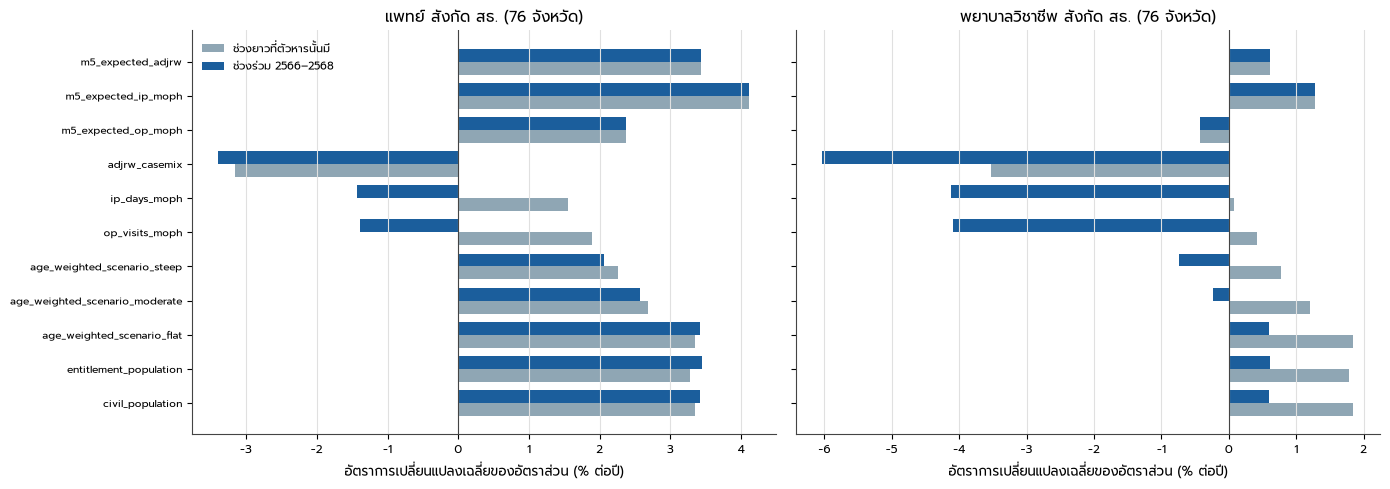

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
order = list(den_series)
for ax, c in zip(axes, ["แพทย์", "พยาบาลวิชาชีพ"]):
    for j, (win, col) in enumerate([("long", "#8fa6b4"), ("common_2023_2025", "#1b5e9c")]):
        z = MAT[(MAT.workforce == "moph") & (MAT.cadre == c) & (MAT.window == win)].set_index("denominator").reindex(order)
        ax.barh(np.arange(len(order)) + (j - .5) * .38, z.ratio_cagr_pct, height=.38, color=col,
                label="ช่วงยาวที่ตัวหารนั้นมี" if win == "long" else "ช่วงร่วม 2566–2568")
    ax.axvline(0, color="#444", lw=0.8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7.5); ax.invert_yaxis()
    ax.set_title(f"{c} สังกัด สธ. (76 จังหวัด)"); ax.set_xlabel("อัตราการเปลี่ยนแปลงเฉลี่ยของอัตราส่วน (% ต่อปี)")
    ax.grid(axis="x", color="#e0e0e0")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F424_DENOMINATOR_COMPARISON", fig, MAT, "กำลังคนชุดเดียวกันเมื่อเทียบตัวหารต่างชนิด ช่วงยาวและช่วงร่วม", main=True)
plt.show()

In [28]:
manifest = S.finalize(extra_manifest=dict(folds_seed=MC["cv_seed"], bootstrap_invalid=invalid))
print({k: manifest[k] for k in ["n_tables", "n_figures", "n_claims", "seconds"]})

{'n_tables': 54, 'n_figures': 10, 'n_claims': 1276, 'seconds': 41.7}
